# MQSF - Hands-on

In [1]:
import numpy
import stim

import sinter
import matplotlib.pyplot as plt
from IPython.core.display import Markdown

from tqec.compile.convention import FIXED_BULK_CONVENTION
from tqec.gallery import cnot
from tqec.simulation import start_simulation_using_sinter
from tqec.simulation.generation import generate_stim_circuits_with_detectors
from tqec.simulation.plotting.inset import plot_threshold_as_inset
from tqec.simulation.threshold import binary_search_threshold
from docs.mqsf.utils_simulation import simulate, sample

from tqec.gallery.memory import memory
from tqec import compile_block_graph, Basis, NoiseModel

## A simple memory experiment

In [2]:
SHOTS=1e8

scenarios = dict()

In [3]:
scenario = "Physical"
circuit = stim.Circuit("""
    RX 0
    TICK
    MX 0
    OBSERVABLE_INCLUDE(0) rec[-1]
""")
scenarios[scenario] = circuit
display(Markdown(f"[Open in Crumble ({scenario})]({circuit.to_crumble_url()})"))

[Open in Crumble (Physical)](https://algassert.com/crumble#circuit=RX_0;TICK;MX_0;OI(0)rec[-1]_)

Starting 4 workers...
10 tasks left:
  workers    decoder        eta shots_left errors_left json_metadata                               
        1 pymatching [draining]   99972079         -85 scenario=Physical,per=0.1                   
        1 pymatching          ?  100000000        5000 scenario=Physical,per=0.027825594022071243  
        1 pymatching          ?  100000000        5000 scenario=Physical,per=0.007742636826811269  
        1 pymatching          ?  100000000        5000 scenario=Physical,per=0.002154434690031882  
        0 pymatching        ?·∞  100000000        5000 scenario=Physical,per=0.0005994842503189409 
        0 pymatching        ?·∞  100000000        5000 scenario=Physical,per=0.0001668100537200059 
        0 pymatching        ?·∞  100000000        5000 scenario=Physical,per=4.641588833612772e-05 
        0 pymatching        ?·∞  100000000        5000 scenario=Physical,per=1.2915496650148827e-05
        0 pymatching        ?·∞  100000000        5000 scenario

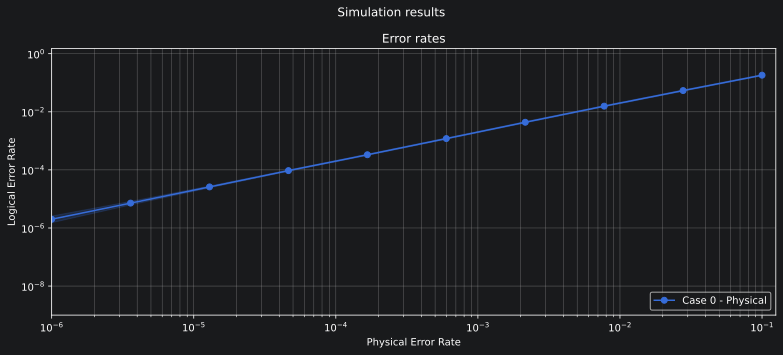

In [4]:
simulate(scenarios, shots=SHOTS, label="Case")

### How to protect this experiment ?

In [5]:
blockgraph = memory(Basis.X)
blockgraph.view_as_html()

In [6]:
for k in range(1,3):
    scenario = f"Surface Code [d={2*k+1}]"
    compiled = compile_block_graph(blockgraph)
    scenarios[scenario] = compiled.generate_stim_circuit(k=k)

    display(Markdown(f"[Open in Crumble ({scenario})]({compiled.generate_crumble_url(k=k)})"))

[Open in Crumble (Surface Code [d=3])](https://algassert.com/crumble#circuit=Q(0,0)0;Q(0,2)1;Q(0,4)2;Q(0,6)3;Q(1,1)4;Q(1,3)5;Q(1,5)6;Q(2,0)7;Q(2,2)8;Q(2,4)9;Q(2,6)10;Q(3,1)11;Q(3,3)12;Q(3,5)13;Q(4,0)14;Q(4,2)15;Q(4,4)16;Q(4,6)17;Q(5,1)18;Q(5,3)19;Q(5,5)20;Q(6,0)21;Q(6,2)22;Q(6,4)23;Q(6,6)24;RX_2_4_5_6_7_8_9_11_12_13_15_16_17_18_19_20_22;TICK;CZ_8_4_16_12_22_18;CX_9_5_15_11_17_13;TICK;CX_9_12_15_18_17_20;CZ_2_5;TICK;CX_7_4_9_6_15_12;CZ_8_5_16_13_22_19;TICK;CZ_8_11_16_19;TICK;CX_7_11_9_13_15_19;CZ_2_6_8_12_16_20;TICK;MX_2_7_8_9_15_16_17_22;DT(2,0,0)rec[-7];DT(4,2,0)rec[-4];DT(2,4,0)rec[-5];DT(4,6,0)rec[-2];SHIFT_COORDS(0,0,1);TICK;RX_2_7_8_9_15_16_17_22;TICK;CZ_8_4_16_12_22_18;CX_9_5_15_11_17_13;TICK;CX_9_12_15_18_17_20;CZ_2_5;TICK;CX_7_4_9_6_15_12;CZ_8_5_16_13_22_19;TICK;CZ_8_11_16_19;TICK;CX_7_11_9_13_15_19;CZ_2_6_8_12_16_20;TICK;MX_2_7_8_9_15_16_17_22;DT(4,2,0)rec[-12]_rec[-4];DT(6,2,0)rec[-9]_rec[-1];DT(2,2,0)rec[-14]_rec[-6];DT(2,0,0)rec[-15]_rec[-7];DT(0,4,0)rec[-16]_rec[-8];DT(2,4,0)rec[-13]_rec[-5];DT(4,4,0)rec[-11]_rec[-3];DT(4,6,0)rec[-10]_rec[-2];SHIFT_COORDS(0,0,1);TICK;RX_2_7_8_9_15_16_17_22;TICK;CZ_8_4_16_12_22_18;CX_9_5_15_11_17_13;TICK;CX_9_12_15_18_17_20;CZ_2_5;TICK;CX_7_4_9_6_15_12;CZ_8_5_16_13_22_19;TICK;CZ_8_11_16_19;TICK;CX_7_11_9_13_15_19;CZ_2_6_8_12_16_20;TICK;MX_2_4_5_6_7_8_9_11_12_13_15_16_17_18_19_20_22;DT(4,6,0)rec[-8]_rec[-5]_rec[-2];DT(4,2,0)rec[-21]_rec[-7];DT(2,2,0)rec[-23]_rec[-12];DT(2,0,0)rec[-24]_rec[-13];DT(4,2,0)rec[-10]_rec[-9]_rec[-7]_rec[-4]_rec[-3];DT(6,2,0)rec[-18]_rec[-1];DT(2,0,0)rec[-16]_rec[-13]_rec[-10];DT(0,4,0)rec[-25]_rec[-17];DT(2,4,0)rec[-15]_rec[-14]_rec[-11]_rec[-9]_rec[-8];DT(2,4,0)rec[-22]_rec[-11];DT(4,4,0)rec[-20]_rec[-6];DT(4,6,0)rec[-19]_rec[-5];OI(0)rec[-10]_rec[-9]_rec[-8];SHIFT_COORDS(0,0,1)_)

[Open in Crumble (Surface Code [d=5])](https://algassert.com/crumble#circuit=Q(0,0)0;Q(0,2)1;Q(0,4)2;Q(0,6)3;Q(0,8)4;Q(0,10)5;Q(1,1)6;Q(1,3)7;Q(1,5)8;Q(1,7)9;Q(1,9)10;Q(2,0)11;Q(2,2)12;Q(2,4)13;Q(2,6)14;Q(2,8)15;Q(2,10)16;Q(3,1)17;Q(3,3)18;Q(3,5)19;Q(3,7)20;Q(3,9)21;Q(4,0)22;Q(4,2)23;Q(4,4)24;Q(4,6)25;Q(4,8)26;Q(4,10)27;Q(5,1)28;Q(5,3)29;Q(5,5)30;Q(5,7)31;Q(5,9)32;Q(6,0)33;Q(6,2)34;Q(6,4)35;Q(6,6)36;Q(6,8)37;Q(6,10)38;Q(7,1)39;Q(7,3)40;Q(7,5)41;Q(7,7)42;Q(7,9)43;Q(8,0)44;Q(8,2)45;Q(8,4)46;Q(8,6)47;Q(8,8)48;Q(8,10)49;Q(9,1)50;Q(9,3)51;Q(9,5)52;Q(9,7)53;Q(9,9)54;Q(10,0)55;Q(10,2)56;Q(10,4)57;Q(10,6)58;Q(10,8)59;Q(10,10)60;RX_2_4_6_7_8_9_10_11_12_13_14_15_17_18_19_20_21_23_24_25_26_27_28_29_30_31_32_33_34_35_36_37_39_40_41_42_43_45_46_47_48_49_50_51_52_53_54_56_58;TICK;CZ_12_6_14_8_24_18_26_20_34_28_36_30_46_40_48_42_56_50_58_52;CX_13_7_15_9_23_17_25_19_27_21_35_29_37_31_45_39_47_41_49_43;TICK;CX_13_18_15_20_23_28_25_30_27_32_35_40_37_42_45_50_47_52_49_54;CZ_2_7_4_9;TICK;CX_11_6_13_8_15_10_23_18_25_20_33_28_35_30_37_32_45_40_47_42;CZ_12_7_14_9_24_19_26_21_34_29_36_31_46_41_48_43_56_51_58_53;TICK;CZ_12_17_14_19_24_29_26_31_34_39_36_41_46_51_48_53;TICK;CX_11_17_13_19_15_21_23_29_25_31_33_39_35_41_37_43_45_51_47_53;CZ_2_8_4_10_12_18_14_20_24_30_26_32_34_40_36_42_46_52_48_54;TICK;MX_2_4_11_12_13_14_15_23_24_25_26_27_33_34_35_36_37_45_46_47_48_49_56_58;DT(8,2,0)rec[-7];DT(6,4,0)rec[-10];DT(4,10,0)rec[-13];DT(4,2,0)rec[-17];DT(4,6,0)rec[-15];DT(6,0,0)rec[-12];DT(2,8,0)rec[-18];DT(2,4,0)rec[-20];DT(8,6,0)rec[-5];DT(2,0,0)rec[-22];DT(8,10,0)rec[-3];DT(6,8,0)rec[-8];SHIFT_COORDS(0,0,1);REPEAT_3_{;TICK;RX_2_4_11_12_13_14_15_23_24_25_26_27_33_34_35_36_37_45_46_47_48_49_56_58;TICK;CZ_12_6_14_8_24_18_26_20_34_28_36_30_46_40_48_42_56_50_58_52;CX_13_7_15_9_23_17_25_19_27_21_35_29_37_31_45_39_47_41_49_43;TICK;CX_13_18_15_20_23_28_25_30_27_32_35_40_37_42_45_50_47_52_49_54;CZ_2_7_4_9;TICK;CX_11_6_13_8_15_10_23_18_25_20_33_28_35_30_37_32_45_40_47_42;CZ_12_7_14_9_24_19_26_21_34_29_36_31_46_41_48_43_56_51_58_53;TICK;CZ_12_17_14_19_24_29_26_31_34_39_36_41_46_51_48_53;TICK;CX_11_17_13_19_15_21_23_29_25_31_33_39_35_41_37_43_45_51_47_53;CZ_2_8_4_10_12_18_14_20_24_30_26_32_34_40_36_42_46_52_48_54;TICK;MX_2_4_11_12_13_14_15_23_24_25_26_27_33_34_35_36_37_45_46_47_48_49_56_58;DT(0,8,0)rec[-47]_rec[-23];DT(2,8,0)rec[-42]_rec[-18];DT(2,2,0)rec[-45]_rec[-21];DT(4,2,0)rec[-41]_rec[-17];DT(6,0,0)rec[-36]_rec[-12];DT(2,0,0)rec[-46]_rec[-22];DT(6,2,0)rec[-35]_rec[-11];DT(8,2,0)rec[-31]_rec[-7];DT(10,2,0)rec[-26]_rec[-2];DT(0,4,0)rec[-48]_rec[-24];DT(6,8,0)rec[-32]_rec[-8];DT(8,8,0)rec[-28]_rec[-4];DT(4,10,0)rec[-37]_rec[-13];DT(8,10,0)rec[-27]_rec[-3];DT(2,4,0)rec[-44]_rec[-20];DT(4,4,0)rec[-40]_rec[-16];DT(6,4,0)rec[-34]_rec[-10];DT(8,4,0)rec[-30]_rec[-6];DT(2,6,0)rec[-43]_rec[-19];DT(4,6,0)rec[-39]_rec[-15];DT(6,6,0)rec[-33]_rec[-9];DT(8,6,0)rec[-29]_rec[-5];DT(10,6,0)rec[-25]_rec[-1];DT(4,8,0)rec[-38]_rec[-14];SHIFT_COORDS(0,0,1);};TICK;RX_2_4_11_12_13_14_15_23_24_25_26_27_33_34_35_36_37_45_46_47_48_49_56_58;TICK;CZ_12_6_14_8_24_18_26_20_34_28_36_30_46_40_48_42_56_50_58_52;CX_13_7_15_9_23_17_25_19_27_21_35_29_37_31_45_39_47_41_49_43;TICK;CX_13_18_15_20_23_28_25_30_27_32_35_40_37_42_45_50_47_52_49_54;CZ_2_7_4_9;TICK;CX_11_6_13_8_15_10_23_18_25_20_33_28_35_30_37_32_45_40_47_42;CZ_12_7_14_9_24_19_26_21_34_29_36_31_46_41_48_43_56_51_58_53;TICK;CZ_12_17_14_19_24_29_26_31_34_39_36_41_46_51_48_53;TICK;CX_11_17_13_19_15_21_23_29_25_31_33_39_35_41_37_43_45_51_47_53;CZ_2_8_4_10_12_18_14_20_24_30_26_32_34_40_36_42_46_52_48_54;TICK;MX_2_4_6_7_8_9_10_11_12_13_14_15_17_18_19_20_21_23_24_25_26_27_28_29_30_31_32_33_34_35_36_37_39_40_41_42_43_45_46_47_48_49_50_51_52_53_54_56_58;DT(8,2,0)rec[-17]_rec[-16]_rec[-12]_rec[-7]_rec[-6];DT(8,6,0)rec[-15]_rec[-14]_rec[-10]_rec[-5]_rec[-4];DT(4,2,0)rec[-37]_rec[-36]_rec[-32]_rec[-27]_rec[-26];DT(6,8,0)rec[-24]_rec[-23]_rec[-18]_rec[-14]_rec[-13];DT(6,4,0)rec[-26]_rec[-25]_rec[-20]_rec[-16]_rec[-15];DT(4,10,0)rec[-33]_rec[-28]_rec[-23];DT(8,10,0)rec[-13]_rec[-8]_rec[-3];DT(6,0,0)rec[-27]_rec[-22]_rec[-17];DT(2,2,0)rec[-70]_rec[-41];DT(6,0,0)rec[-61]_rec[-22];DT(2,0,0)rec[-71]_rec[-42];DT(4,2,0)rec[-66]_rec[-32];DT(6,2,0)rec[-60]_rec[-21];DT(8,2,0)rec[-56]_rec[-12];DT(10,2,0)rec[-51]_rec[-2];DT(0,4,0)rec[-73]_rec[-49];DT(2,4,0)rec[-69]_rec[-40];DT(4,4,0)rec[-65]_rec[-31];DT(4,8,0)rec[-63]_rec[-29];DT(6,8,0)rec[-57]_rec[-18];DT(8,8,0)rec[-53]_rec[-9];DT(4,10,0)rec[-62]_rec[-28];DT(8,10,0)rec[-52]_rec[-8];DT(4,6,0)rec[-35]_rec[-34]_rec[-30]_rec[-25]_rec[-24];DT(2,8,0)rec[-44]_rec[-43]_rec[-38]_rec[-34]_rec[-33];DT(2,0,0)rec[-47]_rec[-42]_rec[-37];DT(2,4,0)rec[-46]_rec[-45]_rec[-40]_rec[-36]_rec[-35];DT(6,4,0)rec[-59]_rec[-20];DT(8,4,0)rec[-55]_rec[-11];DT(2,6,0)rec[-68]_rec[-39];DT(4,6,0)rec[-64]_rec[-30];DT(6,6,0)rec[-58]_rec[-19];DT(8,6,0)rec[-54]_rec[-10];DT(10,6,0)rec[-50]_rec[-1];DT(0,8,0)rec[-72]_rec[-48];DT(2,8,0)rec[-67]_rec[-38];OI(0)rec[-27]_rec[-26]_rec[-25]_rec[-24]_rec[-23];SHIFT_COORDS(0,0,1)_)

Starting 4 workers...
30 tasks left:
  workers    decoder        eta shots_left errors_left json_metadata                                         
        1 pymatching [draining]   99972079        -107 scenario=Physical,per=0.1                             
        1 pymatching          ?  100000000        5000 scenario=Physical,per=0.027825594022071243            
        1 pymatching          ?  100000000        5000 scenario=Physical,per=0.007742636826811269            
        1 pymatching          ?  100000000        5000 scenario=Physical,per=0.002154434690031882            
        0 pymatching        ?·∞  100000000        5000 scenario=Physical,per=0.0005994842503189409           
        0 pymatching        ?·∞  100000000        5000 scenario=Physical,per=0.0001668100537200059           
        0 pymatching        ?·∞  100000000        5000 scenario=Physical,per=4.641588833612772e-05           
        0 pymatching        ?·∞  100000000        5000 scenario=Physical,per=1.2915

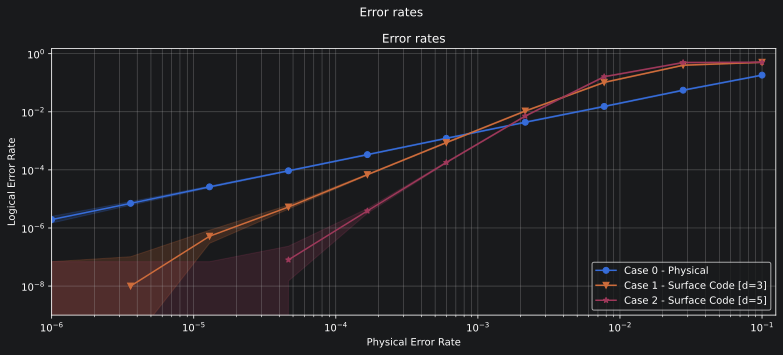

In [7]:
simulate(scenarios, title="Error rates", shots=SHOTS, label="Case")

## Improving resilience to errors

In [8]:
MAX_SHOTS = 1_000_000
MAX_ERRORS = 5000

ler_per_curve_stats = start_simulation_using_sinter(
    blockgraph,
    ks = range(1, 9),
    ps = list(numpy.logspace(-4, -1, 10)),
    noise_model_factory=NoiseModel.uniform_depolarizing,
    manhattan_radius=2,
    convention=FIXED_BULK_CONVENTION,
    observables=blockgraph.find_correlation_surfaces(),
    max_shots=MAX_SHOTS,
    max_errors=MAX_ERRORS,
    decoders=["pymatching"],
    split_observable_stats=False,
)

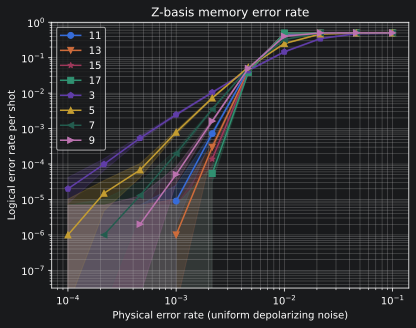

In [9]:
%matplotlib inline
import matplotlib.pyplot as plt

zx_graph = blockgraph.to_zx_graph()
for i, obs in enumerate(blockgraph.find_correlation_surfaces()):
    main_stats = ler_per_curve_stats[i]

    fig, ax = plt.subplots()
    sinter.plot_error_rate(
        ax=ax,
        stats=main_stats,
        x_func=lambda stat: stat.json_metadata["p"],
        group_func=lambda stat: stat.json_metadata["d"],
    )
    ax.grid(which="both", axis="both")
    ax.legend()
    ax.loglog()
    ax.set_title("Z-basis memory error rate")
    ax.set_xlabel("Physical error rate (uniform depolarizing noise)")
    ax.set_ylabel("Logical error rate per shot")
    ax.set_ylim(10**-7.5, 10**0)

## How to perform a CNOT ?

In [10]:
scenario = "Physical"
circuit = stim.Circuit("""
    RX 0
    RZ 1
    TICK
    CX 0 1
    TICK
    MPP X0*X1
    OBSERVABLE_INCLUDE(0) rec[-1]
""")
scenarios[scenario] = circuit
display(Markdown(f"[Open in Crumble ({scenario})]({circuit.to_crumble_url()})"))

[Open in Crumble (Physical)](https://algassert.com/crumble#circuit=RX_0;R_1;TICK;CX_0_1;TICK;MPP_X0*X1;OI(0)rec[-1]_)

### And how to protect it ?

In [11]:
blockgraph = cnot(Basis.X)
blockgraph.view_as_html()

In [12]:
for k in range(1,3):
    scenario = f"Surface Code [d={2*k+1}]"
    compiled = compile_block_graph(blockgraph)
    scenarios[scenario] = compiled.generate_stim_circuit(k=k)

    display(Markdown(f"[Open in Crumble ({scenario})]({compiled.generate_crumble_url(k=k)})"))

[Open in Crumble (Surface Code [d=3])](https://algassert.com/crumble#circuit=Q(0,0)0;Q(0,2)1;Q(0,4)2;Q(0,6)3;Q(0,8)4;Q(0,10)5;Q(0,12)6;Q(0,14)7;Q(1,1)8;Q(1,3)9;Q(1,5)10;Q(1,7)11;Q(1,9)12;Q(1,11)13;Q(1,13)14;Q(2,0)15;Q(2,2)16;Q(2,4)17;Q(2,6)18;Q(2,8)19;Q(2,10)20;Q(2,12)21;Q(2,14)22;Q(3,1)23;Q(3,3)24;Q(3,5)25;Q(3,7)26;Q(3,9)27;Q(3,11)28;Q(3,13)29;Q(4,0)30;Q(4,2)31;Q(4,4)32;Q(4,6)33;Q(4,8)34;Q(4,10)35;Q(4,12)36;Q(4,14)37;Q(5,1)38;Q(5,3)39;Q(5,5)40;Q(5,7)41;Q(5,9)42;Q(5,11)43;Q(5,13)44;Q(6,0)45;Q(6,2)46;Q(6,4)47;Q(6,6)48;Q(6,8)49;Q(6,10)50;Q(6,12)51;Q(6,14)52;Q(7,9)53;Q(7,11)54;Q(7,13)55;Q(8,8)56;Q(8,10)57;Q(8,12)58;Q(8,14)59;Q(9,9)60;Q(9,11)61;Q(9,13)62;Q(10,8)63;Q(10,10)64;Q(10,12)65;Q(10,14)66;Q(11,9)67;Q(11,11)68;Q(11,13)69;Q(12,8)70;Q(12,10)71;Q(12,12)72;Q(12,14)73;Q(13,9)74;Q(13,11)75;Q(13,13)76;Q(14,8)77;Q(14,10)78;Q(14,12)79;Q(14,14)80;RX_2_8_9_10_15_16_17_23_24_25_31_32_33_38_39_40_46_58_60_61_62_63_64_65_67_68_69_71_72_73_74_75_76_78;TICK;CZ_16_8_32_24_46_38_64_60_72_68_78_74;CX_17_9_31_23_33_25_65_61_71_67_73_69;TICK;CX_17_24_31_38_33_40_65_68_71_74_73_76;CZ_2_9_58_61;TICK;CX_15_8_17_10_31_24_63_60_65_62_71_68;CZ_16_9_32_25_46_39_64_61_72_69_78_75;TICK;CZ_16_23_32_39_64_67_72_75;TICK;CX_15_23_17_25_31_39_63_67_65_69_71_75;CZ_2_10_16_24_32_40_58_62_64_68_72_76;TICK;MX_2_15_16_17_31_32_33_46_58_63_64_65_71_72_73_78;DT(10,12,0)rec[-5];DT(4,2,0)rec[-12];DT(4,6,0)rec[-10];DT(12,10,0)rec[-4];DT(2,4,0)rec[-13];DT(2,0,0)rec[-15];DT(12,14,0)rec[-2];DT(10,8,0)rec[-7];SHIFT_COORDS(0,0,1);TICK;RX_2_15_16_17_31_32_33_46_58_63_64_65_71_72_73_78;TICK;CZ_16_8_32_24_46_38_64_60_72_68_78_74;CX_17_9_31_23_33_25_65_61_71_67_73_69;TICK;CX_17_24_31_38_33_40_65_68_71_74_73_76;CZ_2_9_58_61;TICK;CX_15_8_17_10_31_24_63_60_65_62_71_68;CZ_16_9_32_25_46_39_64_61_72_69_78_75;TICK;CZ_16_23_32_39_64_67_72_75;TICK;CX_15_23_17_25_31_39_63_67_65_69_71_75;CZ_2_10_16_24_32_40_58_62_64_68_72_76;TICK;MX_2_15_16_17_31_32_33_46_58_63_64_65_71_72_73_78;DT(4,2,0)rec[-28]_rec[-12];DT(6,2,0)rec[-25]_rec[-9];DT(2,2,0)rec[-30]_rec[-14];DT(2,0,0)rec[-31]_rec[-15];DT(0,4,0)rec[-32]_rec[-16];DT(2,4,0)rec[-29]_rec[-13];DT(4,4,0)rec[-27]_rec[-11];DT(4,6,0)rec[-26]_rec[-10];DT(10,8,0)rec[-23]_rec[-7];DT(10,10,0)rec[-22]_rec[-6];DT(12,10,0)rec[-20]_rec[-4];DT(14,10,0)rec[-17]_rec[-1];DT(8,12,0)rec[-24]_rec[-8];DT(10,12,0)rec[-21]_rec[-5];DT(12,12,0)rec[-19]_rec[-3];DT(12,14,0)rec[-18]_rec[-2];SHIFT_COORDS(0,0,1);TICK;RX_2_15_16_17_31_32_33_46_58_63_64_65_71_72_73_78;TICK;CZ_16_8_32_24_46_38_64_60_72_68_78_74;CX_17_9_31_23_33_25_65_61_71_67_73_69;TICK;CX_17_24_31_38_33_40_65_68_71_74_73_76;CZ_2_9_58_61;TICK;CX_15_8_17_10_31_24_63_60_65_62_71_68;CZ_16_9_32_25_46_39_64_61_72_69_78_75;TICK;CZ_16_23_32_39_64_67_72_75;TICK;CX_15_23_17_25_31_39_63_67_65_69_71_75;CZ_2_10_16_24_32_40_58_62_64_68_72_76;TICK;MX_2_15_16_17_31_32_33_46_58_63_64_65_71_72_73_78;DT(4,2,0)rec[-28]_rec[-12];DT(6,2,0)rec[-25]_rec[-9];DT(2,2,0)rec[-30]_rec[-14];DT(2,0,0)rec[-31]_rec[-15];DT(0,4,0)rec[-32]_rec[-16];DT(2,4,0)rec[-29]_rec[-13];DT(4,4,0)rec[-27]_rec[-11];DT(4,6,0)rec[-26]_rec[-10];DT(10,8,0)rec[-23]_rec[-7];DT(10,10,0)rec[-22]_rec[-6];DT(12,10,0)rec[-20]_rec[-4];DT(14,10,0)rec[-17]_rec[-1];DT(8,12,0)rec[-24]_rec[-8];DT(10,12,0)rec[-21]_rec[-5];DT(12,12,0)rec[-19]_rec[-3];DT(12,14,0)rec[-18]_rec[-2];SHIFT_COORDS(0,0,1);TICK;RX_2_4_6_11_12_13_14_15_16_17_18_19_20_21_26_27_28_29_31_32_33_34_35_36_37_41_42_43_44_46_48_50_58_63_64_65_71_72_73_78;TICK;CZ_16_8_18_10_20_12_32_24_34_26_36_28_46_38_48_40_50_42_64_60_72_68_78_74;CX_17_9_19_11_21_13_31_23_33_25_35_27_37_29_65_61_71_67_73_69;TICK;CX_17_24_19_26_21_28_31_38_33_40_35_42_37_44_65_68_71_74_73_76;CZ_2_9_4_11_6_13_58_61;TICK;CX_15_8_17_10_19_12_21_14_31_24_33_26_35_28_63_60_65_62_71_68;CZ_16_9_18_11_20_13_32_25_34_27_36_29_46_39_48_41_50_43_64_61_72_69_78_75;TICK;CZ_16_23_18_25_20_27_32_39_34_41_36_43_64_67_72_75;TICK;CX_15_23_17_25_19_27_21_29_31_39_33_41_35_43_63_67_65_69_71_75;CZ_2_10_4_12_6_14_16_24_18_26_20_28_32_40_34_42_36_44_58_62_64_68_72_76;TICK;MX_2_4_6_15_16_17_18_19_20_21_31_32_33_34_35_36_37_46_48_50_58_63_64_65_71_72_73_78;DT(2,8,0)rec[-21];DT(4,10,0)rec[-14];DT(4,14,0)rec[-12];DT(4,2,0)rec[-40]_rec[-18];DT(6,2,0)rec[-37]_rec[-11];DT(2,2,0)rec[-42]_rec[-24];DT(2,0,0)rec[-43]_rec[-25];DT(0,4,0)rec[-44]_rec[-28];DT(2,4,0)rec[-41]_rec[-23];DT(4,4,0)rec[-39]_rec[-17];DT(4,6,0)rec[-38]_rec[-16];DT(10,8,0)rec[-35]_rec[-7];DT(10,10,0)rec[-34]_rec[-6];DT(2,12,0)rec[-19];DT(12,10,0)rec[-32]_rec[-4];DT(14,10,0)rec[-29]_rec[-1];DT(8,12,0)rec[-36]_rec[-8];DT(10,12,0)rec[-33]_rec[-5];DT(12,12,0)rec[-31]_rec[-3];DT(12,14,0)rec[-30]_rec[-2];SHIFT_COORDS(0,0,1);TICK;RX_2_4_6_15_16_17_18_19_20_21_31_32_33_34_35_36_37_46_48_50_58_63_64_65_71_72_73_78;TICK;CZ_16_8_18_10_20_12_32_24_34_26_36_28_46_38_48_40_50_42_64_60_72_68_78_74;CX_17_9_19_11_21_13_31_23_33_25_35_27_37_29_65_61_71_67_73_69;TICK;CX_17_24_19_26_21_28_31_38_33_40_35_42_37_44_65_68_71_74_73_76;CZ_2_9_4_11_6_13_58_61;TICK;CX_15_8_17_10_19_12_21_14_31_24_33_26_35_28_63_60_65_62_71_68;CZ_16_9_18_11_20_13_32_25_34_27_36_29_46_39_48_41_50_43_64_61_72_69_78_75;TICK;CZ_16_23_18_25_20_27_32_39_34_41_36_43_64_67_72_75;TICK;CX_15_23_17_25_19_27_21_29_31_39_33_41_35_43_63_67_65_69_71_75;CZ_2_10_4_12_6_14_16_24_18_26_20_28_32_40_34_42_36_44_58_62_64_68_72_76;TICK;MX_2_4_6_15_16_17_18_19_20_21_31_32_33_34_35_36_37_46_48_50_58_63_64_65_71_72_73_78;DT(10,10,0)rec[-34]_rec[-6];DT(12,10,0)rec[-32]_rec[-4];DT(4,2,0)rec[-46]_rec[-18];DT(6,2,0)rec[-39]_rec[-11];DT(2,2,0)rec[-52]_rec[-24];DT(2,0,0)rec[-53]_rec[-25];DT(0,4,0)rec[-56]_rec[-28];DT(2,4,0)rec[-51]_rec[-23];DT(4,4,0)rec[-45]_rec[-17];DT(2,6,0)rec[-50]_rec[-22];DT(0,12,0)rec[-54]_rec[-26];DT(2,12,0)rec[-47]_rec[-19];DT(4,12,0)rec[-41]_rec[-13];DT(8,12,0)rec[-36]_rec[-8];DT(10,12,0)rec[-33]_rec[-5];DT(12,12,0)rec[-31]_rec[-3];DT(4,14,0)rec[-40]_rec[-12];DT(12,14,0)rec[-30]_rec[-2];DT(4,6,0)rec[-44]_rec[-16];DT(6,6,0)rec[-38]_rec[-10];DT(0,8,0)rec[-55]_rec[-27];DT(2,8,0)rec[-49]_rec[-21];DT(4,8,0)rec[-43]_rec[-15];DT(10,8,0)rec[-35]_rec[-7];DT(2,10,0)rec[-48]_rec[-20];DT(4,10,0)rec[-42]_rec[-14];DT(6,10,0)rec[-37]_rec[-9];DT(14,10,0)rec[-29]_rec[-1];SHIFT_COORDS(0,0,1);TICK;RX_2_4_6_15_16_17_18_19_20_21_31_32_33_34_35_36_37_46_48_50_58_63_64_65_71_72_73_78;TICK;CZ_16_8_18_10_20_12_32_24_34_26_36_28_46_38_48_40_50_42_64_60_72_68_78_74;CX_17_9_19_11_21_13_31_23_33_25_35_27_37_29_65_61_71_67_73_69;TICK;CX_17_24_19_26_21_28_31_38_33_40_35_42_37_44_65_68_71_74_73_76;CZ_2_9_4_11_6_13_58_61;TICK;CX_15_8_17_10_19_12_21_14_31_24_33_26_35_28_63_60_65_62_71_68;CZ_16_9_18_11_20_13_32_25_34_27_36_29_46_39_48_41_50_43_64_61_72_69_78_75;TICK;CZ_16_23_18_25_20_27_32_39_34_41_36_43_64_67_72_75;TICK;CX_15_23_17_25_19_27_21_29_31_39_33_41_35_43_63_67_65_69_71_75;CZ_2_10_4_12_6_14_16_24_18_26_20_28_32_40_34_42_36_44_58_62_64_68_72_76;TICK;MX_2_4_6_11_15_16_17_18_19_20_21_26_31_32_33_34_35_36_37_41_46_48_50_58_63_64_65_71_72_73_78;DT(10,10,0)rec[-37]_rec[-6];DT(12,10,0)rec[-35]_rec[-4];DT(4,2,0)rec[-49]_rec[-19];DT(6,2,0)rec[-42]_rec[-11];DT(2,2,0)rec[-55]_rec[-26];DT(2,0,0)rec[-56]_rec[-27];DT(0,4,0)rec[-59]_rec[-31];DT(2,4,0)rec[-54]_rec[-25];DT(4,4,0)rec[-48]_rec[-18];DT(2,6,0)rec[-53]_rec[-24];DT(0,12,0)rec[-57]_rec[-29];DT(2,12,0)rec[-50]_rec[-21];DT(4,12,0)rec[-44]_rec[-14];DT(8,12,0)rec[-39]_rec[-8];DT(10,12,0)rec[-36]_rec[-5];DT(12,12,0)rec[-34]_rec[-3];DT(4,14,0)rec[-43]_rec[-13];DT(12,14,0)rec[-33]_rec[-2];DT(4,6,0)rec[-47]_rec[-17];DT(6,6,0)rec[-41]_rec[-10];DT(0,8,0)rec[-58]_rec[-30];DT(2,8,0)rec[-52]_rec[-23];DT(4,8,0)rec[-46]_rec[-16];DT(10,8,0)rec[-38]_rec[-7];DT(2,10,0)rec[-51]_rec[-22];DT(4,10,0)rec[-45]_rec[-15];DT(6,10,0)rec[-40]_rec[-9];DT(14,10,0)rec[-32]_rec[-1];OI(0)rec[-20];OI(1)rec[-20];SHIFT_COORDS(0,0,1);TICK;RX_2_6_15_16_17_19_20_21_31_32_33_35_36_37_46_49_50_51_57_58_59_63_64_65_71_72_73_78;R_53_54_55;TICK;CZ_16_8_20_12_32_24_36_28_46_38_50_42_58_54_64_60_72_68_78_74;CX_17_9_21_13_31_23_33_25_35_27_37_29_51_43_57_53_59_55_65_61_71_67_73_69;TICK;CX_17_24_21_28_31_38_33_40_35_42_37_44_51_54_57_60_59_62_65_68_71_74_73_76;CZ_2_9_6_13;TICK;CX_15_8_17_10_19_12_21_14_31_24_35_28_49_42_51_44_57_54_63_60_65_62_71_68;CZ_16_9_20_13_32_25_36_29_46_39_50_43_58_55_64_61_72_69_78_75;TICK;CZ_16_23_20_27_32_39_36_43_50_53_58_61_64_67_72_75;TICK;CX_15_23_17_25_19_27_21_29_31_39_35_43_49_53_51_55_57_61_63_67_65_69_71_75;CZ_2_10_6_14_16_24_20_28_32_40_36_44_50_54_58_62_64_68_72_76;TICK;MX_2_6_15_16_17_19_20_21_31_32_33_35_36_37_46_49_50_51_57_58_59_63_64_65_71_72_73_78;DT(2,8,0)rec[-56]_rec[-51]_rec[-48]_rec[-23];DT(4,6,0)rec[-48]_rec[-45]_rec[-40]_rec[-18];DT(4,2,0)rec[-47]_rec[-20];DT(6,2,0)rec[-39]_rec[-14];DT(2,2,0)rec[-54]_rec[-25];DT(2,0,0)rec[-55]_rec[-26];DT(0,4,0)rec[-59]_rec[-28];DT(2,4,0)rec[-53]_rec[-24];DT(4,4,0)rec[-46]_rec[-19];DT(10,8,0)rec[-35]_rec[-7];DT(2,10,0)rec[-50]_rec[-22];DT(4,10,0)rec[-43]_rec[-17];DT(4,14,0)rec[-41]_rec[-15];DT(12,14,0)rec[-30]_rec[-2];DT(6,10,0)rec[-37]_rec[-12];DT(10,10,0)rec[-34]_rec[-6];DT(12,10,0)rec[-32]_rec[-4];DT(14,10,0)rec[-29]_rec[-1];DT(0,12,0)rec[-57]_rec[-27];DT(2,12,0)rec[-49]_rec[-21];DT(4,12,0)rec[-42]_rec[-16];DT(8,12,0)rec[-36]_rec[-9];DT(10,12,0)rec[-33]_rec[-5];DT(12,12,0)rec[-31]_rec[-3];OI(0)rec[-17]_rec[-15]_rec[-13]_rec[-11]_rec[-10]_rec[-8]_rec[-7]_rec[-5];OI(1)rec[-17]_rec[-15]_rec[-13]_rec[-11]_rec[-10]_rec[-8]_rec[-7]_rec[-5];SHIFT_COORDS(0,0,1);TICK;RX_2_6_15_16_17_19_20_21_31_32_33_35_36_37_46_49_50_51_57_58_59_63_64_65_71_72_73_78;TICK;CZ_16_8_20_12_32_24_36_28_46_38_50_42_58_54_64_60_72_68_78_74;CX_17_9_21_13_31_23_33_25_35_27_37_29_51_43_57_53_59_55_65_61_71_67_73_69;TICK;CX_17_24_21_28_31_38_33_40_35_42_37_44_51_54_57_60_59_62_65_68_71_74_73_76;CZ_2_9_6_13;TICK;CX_15_8_17_10_19_12_21_14_31_24_35_28_49_42_51_44_57_54_63_60_65_62_71_68;CZ_16_9_20_13_32_25_36_29_46_39_50_43_58_55_64_61_72_69_78_75;TICK;CZ_16_23_20_27_32_39_36_43_50_53_58_61_64_67_72_75;TICK;CX_15_23_17_25_19_27_21_29_31_39_35_43_49_53_51_55_57_61_63_67_65_69_71_75;CZ_2_10_6_14_16_24_20_28_32_40_36_44_50_54_58_62_64_68_72_76;TICK;MX_2_6_15_16_17_19_20_21_31_32_33_35_36_37_46_49_50_51_57_58_59_63_64_65_71_72_73_78;DT(14,10,0)rec[-29]_rec[-1];DT(0,12,0)rec[-55]_rec[-27];DT(4,2,0)rec[-48]_rec[-20];DT(6,2,0)rec[-42]_rec[-14];DT(2,2,0)rec[-53]_rec[-25];DT(2,0,0)rec[-54]_rec[-26];DT(0,4,0)rec[-56]_rec[-28];DT(2,4,0)rec[-52]_rec[-24];DT(4,4,0)rec[-47]_rec[-19];DT(4,6,0)rec[-46]_rec[-18];DT(4,12,0)rec[-44]_rec[-16];DT(6,12,0)rec[-39]_rec[-11];DT(8,12,0)rec[-37]_rec[-9];DT(10,12,0)rec[-33]_rec[-5];DT(12,12,0)rec[-31]_rec[-3];DT(4,14,0)rec[-43]_rec[-15];DT(8,14,0)rec[-36]_rec[-8];DT(12,14,0)rec[-30]_rec[-2];DT(2,8,0)rec[-51]_rec[-23];DT(6,8,0)rec[-41]_rec[-13];DT(10,8,0)rec[-35]_rec[-7];DT(2,10,0)rec[-50]_rec[-22];DT(4,10,0)rec[-45]_rec[-17];DT(6,10,0)rec[-40]_rec[-12];DT(8,10,0)rec[-38]_rec[-10];DT(10,10,0)rec[-34]_rec[-6];DT(12,10,0)rec[-32]_rec[-4];DT(2,12,0)rec[-49]_rec[-21];SHIFT_COORDS(0,0,1);TICK;RX_2_6_15_16_17_19_20_21_31_32_33_35_36_37_46_49_50_51_57_58_59_63_64_65_71_72_73_78;TICK;CZ_16_8_20_12_32_24_36_28_46_38_50_42_58_54_64_60_72_68_78_74;CX_17_9_21_13_31_23_33_25_35_27_37_29_51_43_57_53_59_55_65_61_71_67_73_69;TICK;CX_17_24_21_28_31_38_33_40_35_42_37_44_51_54_57_60_59_62_65_68_71_74_73_76;CZ_2_9_6_13;TICK;CX_15_8_17_10_19_12_21_14_31_24_35_28_49_42_51_44_57_54_63_60_65_62_71_68;CZ_16_9_20_13_32_25_36_29_46_39_50_43_58_55_64_61_72_69_78_75;TICK;CZ_16_23_20_27_32_39_36_43_50_53_58_61_64_67_72_75;TICK;CX_15_23_17_25_19_27_21_29_31_39_35_43_49_53_51_55_57_61_63_67_65_69_71_75;CZ_2_10_6_14_16_24_20_28_32_40_36_44_50_54_58_62_64_68_72_76;TICK;MX_2_6_15_16_17_19_20_21_31_32_33_35_36_37_46_49_50_51_57_58_59_63_64_65_71_72_73_78;M_12_13_14_27_28_29_42_43_44_53_54_55;DT(0,12,0)rec[-39]_rec[-11]_rec[-10];DT(6,10,0)rec[-24]_rec[-6]_rec[-5]_rec[-3]_rec[-2];DT(4,12,0)rec[-28]_rec[-8]_rec[-7]_rec[-5]_rec[-4];DT(2,10,0)rec[-34]_rec[-12]_rec[-11]_rec[-9]_rec[-8];DT(12,10,0)rec[-44]_rec[-16];DT(4,2,0)rec[-60]_rec[-32];DT(6,2,0)rec[-54]_rec[-26];DT(2,2,0)rec[-65]_rec[-37];DT(2,0,0)rec[-66]_rec[-38];DT(0,4,0)rec[-68]_rec[-40];DT(2,4,0)rec[-64]_rec[-36];DT(4,4,0)rec[-59]_rec[-31];DT(4,6,0)rec[-58]_rec[-30];DT(2,8,0)rec[-63]_rec[-35];DT(4,12,0)rec[-56]_rec[-28];DT(6,12,0)rec[-51]_rec[-23];DT(8,12,0)rec[-49]_rec[-21];DT(10,12,0)rec[-45]_rec[-17];DT(12,12,0)rec[-43]_rec[-15];DT(4,14,0)rec[-55]_rec[-27];DT(8,14,0)rec[-48]_rec[-20];DT(12,14,0)rec[-42]_rec[-14];DT(6,8,0)rec[-53]_rec[-25];DT(10,8,0)rec[-47]_rec[-19];DT(2,10,0)rec[-62]_rec[-34];DT(4,10,0)rec[-57]_rec[-29];DT(6,10,0)rec[-52]_rec[-24];DT(8,10,0)rec[-50]_rec[-22];DT(10,10,0)rec[-46]_rec[-18];DT(14,10,0)rec[-41]_rec[-13];DT(0,12,0)rec[-67]_rec[-39];DT(2,12,0)rec[-61]_rec[-33];SHIFT_COORDS(0,0,1);TICK;RX_2_15_16_17_31_32_33_46_58_63_64_65_71_72_73_78;TICK;CZ_16_8_32_24_46_38_64_60_72_68_78_74;CX_17_9_31_23_33_25_65_61_71_67_73_69;TICK;CX_17_24_31_38_33_40_65_68_71_74_73_76;CZ_2_9_58_61;TICK;CX_15_8_17_10_31_24_63_60_65_62_71_68;CZ_16_9_32_25_46_39_64_61_72_69_78_75;TICK;CZ_16_23_32_39_64_67_72_75;TICK;CX_15_23_17_25_31_39_63_67_65_69_71_75;CZ_2_10_16_24_32_40_58_62_64_68_72_76;TICK;MX_2_15_16_17_31_32_33_46_58_63_64_65_71_72_73_78;DT(8,12,0)rec[-37]_rec[-18]_rec[-17]_rec[-8];DT(4,2,0)rec[-48]_rec[-12];DT(6,2,0)rec[-42]_rec[-9];DT(2,2,0)rec[-53]_rec[-14];DT(2,0,0)rec[-54]_rec[-15];DT(0,4,0)rec[-56]_rec[-16];DT(2,4,0)rec[-52]_rec[-13];DT(4,4,0)rec[-47]_rec[-11];DT(4,6,0)rec[-46]_rec[-10];DT(10,8,0)rec[-35]_rec[-7];DT(10,10,0)rec[-34]_rec[-6];DT(12,10,0)rec[-32]_rec[-4];DT(14,10,0)rec[-29]_rec[-1];DT(10,12,0)rec[-33]_rec[-5];DT(12,12,0)rec[-31]_rec[-3];DT(12,14,0)rec[-30]_rec[-2];SHIFT_COORDS(0,0,1);TICK;RX_2_15_16_17_31_32_33_46_58_63_64_65_71_72_73_78;TICK;CZ_16_8_32_24_46_38_64_60_72_68_78_74;CX_17_9_31_23_33_25_65_61_71_67_73_69;TICK;CX_17_24_31_38_33_40_65_68_71_74_73_76;CZ_2_9_58_61;TICK;CX_15_8_17_10_31_24_63_60_65_62_71_68;CZ_16_9_32_25_46_39_64_61_72_69_78_75;TICK;CZ_16_23_32_39_64_67_72_75;TICK;CX_15_23_17_25_31_39_63_67_65_69_71_75;CZ_2_10_16_24_32_40_58_62_64_68_72_76;TICK;MX_2_15_16_17_31_32_33_46_58_63_64_65_71_72_73_78;DT(4,2,0)rec[-28]_rec[-12];DT(6,2,0)rec[-25]_rec[-9];DT(2,2,0)rec[-30]_rec[-14];DT(2,0,0)rec[-31]_rec[-15];DT(0,4,0)rec[-32]_rec[-16];DT(2,4,0)rec[-29]_rec[-13];DT(4,4,0)rec[-27]_rec[-11];DT(4,6,0)rec[-26]_rec[-10];DT(10,8,0)rec[-23]_rec[-7];DT(10,10,0)rec[-22]_rec[-6];DT(12,10,0)rec[-20]_rec[-4];DT(14,10,0)rec[-17]_rec[-1];DT(8,12,0)rec[-24]_rec[-8];DT(10,12,0)rec[-21]_rec[-5];DT(12,12,0)rec[-19]_rec[-3];DT(12,14,0)rec[-18]_rec[-2];SHIFT_COORDS(0,0,1);TICK;RX_2_15_16_17_31_32_33_46_58_63_64_65_71_72_73_78;TICK;CZ_16_8_32_24_46_38_64_60_72_68_78_74;CX_17_9_31_23_33_25_65_61_71_67_73_69;TICK;CX_17_24_31_38_33_40_65_68_71_74_73_76;CZ_2_9_58_61;TICK;CX_15_8_17_10_31_24_63_60_65_62_71_68;CZ_16_9_32_25_46_39_64_61_72_69_78_75;TICK;CZ_16_23_32_39_64_67_72_75;TICK;CX_15_23_17_25_31_39_63_67_65_69_71_75;CZ_2_10_16_24_32_40_58_62_64_68_72_76;TICK;MX_2_8_9_10_15_16_17_23_24_25_31_32_33_38_39_40_46_58_60_61_62_63_64_65_67_68_69_71_72_73_74_75_76_78;DT(12,10,0)rec[-10]_rec[-9]_rec[-7]_rec[-4]_rec[-3];DT(4,6,0)rec[-25]_rec[-22]_rec[-19];DT(4,2,0)rec[-27]_rec[-26]_rec[-24]_rec[-21]_rec[-20];DT(10,12,0)rec[-15]_rec[-14]_rec[-11]_rec[-9]_rec[-8];DT(4,2,0)rec[-46]_rec[-24];DT(2,2,0)rec[-48]_rec[-29];DT(2,0,0)rec[-49]_rec[-30];DT(6,2,0)rec[-43]_rec[-18];DT(0,4,0)rec[-50]_rec[-34];DT(2,4,0)rec[-47]_rec[-28];DT(4,4,0)rec[-45]_rec[-23];DT(4,6,0)rec[-44]_rec[-22];DT(10,8,0)rec[-41]_rec[-13];DT(10,10,0)rec[-40]_rec[-12];DT(12,14,0)rec[-8]_rec[-5]_rec[-2];DT(10,8,0)rec[-16]_rec[-13]_rec[-10];DT(2,0,0)rec[-33]_rec[-30]_rec[-27];DT(2,4,0)rec[-32]_rec[-31]_rec[-28]_rec[-26]_rec[-25];DT(12,10,0)rec[-38]_rec[-7];DT(14,10,0)rec[-35]_rec[-1];DT(8,12,0)rec[-42]_rec[-17];DT(10,12,0)rec[-39]_rec[-11];DT(12,12,0)rec[-37]_rec[-6];DT(12,14,0)rec[-36]_rec[-5];OI(0)rec[-27]_rec[-26]_rec[-25];OI(1)rec[-27]_rec[-26]_rec[-25]_rec[-10]_rec[-9]_rec[-8];SHIFT_COORDS(0,0,1)_)

[Open in Crumble (Surface Code [d=5])](https://algassert.com/crumble#circuit=Q(0,0)0;Q(0,2)1;Q(0,4)2;Q(0,6)3;Q(0,8)4;Q(0,10)5;Q(0,12)6;Q(0,14)7;Q(0,16)8;Q(0,18)9;Q(0,20)10;Q(0,22)11;Q(1,1)12;Q(1,3)13;Q(1,5)14;Q(1,7)15;Q(1,9)16;Q(1,11)17;Q(1,13)18;Q(1,15)19;Q(1,17)20;Q(1,19)21;Q(1,21)22;Q(2,0)23;Q(2,2)24;Q(2,4)25;Q(2,6)26;Q(2,8)27;Q(2,10)28;Q(2,12)29;Q(2,14)30;Q(2,16)31;Q(2,18)32;Q(2,20)33;Q(2,22)34;Q(3,1)35;Q(3,3)36;Q(3,5)37;Q(3,7)38;Q(3,9)39;Q(3,11)40;Q(3,13)41;Q(3,15)42;Q(3,17)43;Q(3,19)44;Q(3,21)45;Q(4,0)46;Q(4,2)47;Q(4,4)48;Q(4,6)49;Q(4,8)50;Q(4,10)51;Q(4,12)52;Q(4,14)53;Q(4,16)54;Q(4,18)55;Q(4,20)56;Q(4,22)57;Q(5,1)58;Q(5,3)59;Q(5,5)60;Q(5,7)61;Q(5,9)62;Q(5,11)63;Q(5,13)64;Q(5,15)65;Q(5,17)66;Q(5,19)67;Q(5,21)68;Q(6,0)69;Q(6,2)70;Q(6,4)71;Q(6,6)72;Q(6,8)73;Q(6,10)74;Q(6,12)75;Q(6,14)76;Q(6,16)77;Q(6,18)78;Q(6,20)79;Q(6,22)80;Q(7,1)81;Q(7,3)82;Q(7,5)83;Q(7,7)84;Q(7,9)85;Q(7,11)86;Q(7,13)87;Q(7,15)88;Q(7,17)89;Q(7,19)90;Q(7,21)91;Q(8,0)92;Q(8,2)93;Q(8,4)94;Q(8,6)95;Q(8,8)96;Q(8,10)97;Q(8,12)98;Q(8,14)99;Q(8,16)100;Q(8,18)101;Q(8,20)102;Q(8,22)103;Q(9,1)104;Q(9,3)105;Q(9,5)106;Q(9,7)107;Q(9,9)108;Q(9,11)109;Q(9,13)110;Q(9,15)111;Q(9,17)112;Q(9,19)113;Q(9,21)114;Q(10,0)115;Q(10,2)116;Q(10,4)117;Q(10,6)118;Q(10,8)119;Q(10,10)120;Q(10,12)121;Q(10,14)122;Q(10,16)123;Q(10,18)124;Q(10,20)125;Q(10,22)126;Q(11,13)127;Q(11,15)128;Q(11,17)129;Q(11,19)130;Q(11,21)131;Q(12,12)132;Q(12,14)133;Q(12,16)134;Q(12,18)135;Q(12,20)136;Q(12,22)137;Q(13,13)138;Q(13,15)139;Q(13,17)140;Q(13,19)141;Q(13,21)142;Q(14,12)143;Q(14,14)144;Q(14,16)145;Q(14,18)146;Q(14,20)147;Q(14,22)148;Q(15,13)149;Q(15,15)150;Q(15,17)151;Q(15,19)152;Q(15,21)153;Q(16,12)154;Q(16,14)155;Q(16,16)156;Q(16,18)157;Q(16,20)158;Q(16,22)159;Q(17,13)160;Q(17,15)161;Q(17,17)162;Q(17,19)163;Q(17,21)164;Q(18,12)165;Q(18,14)166;Q(18,16)167;Q(18,18)168;Q(18,20)169;Q(18,22)170;Q(19,13)171;Q(19,15)172;Q(19,17)173;Q(19,19)174;Q(19,21)175;Q(20,12)176;Q(20,14)177;Q(20,16)178;Q(20,18)179;Q(20,20)180;Q(20,22)181;Q(21,13)182;Q(21,15)183;Q(21,17)184;Q(21,19)185;Q(21,21)186;Q(22,12)187;Q(22,14)188;Q(22,16)189;Q(22,18)190;Q(22,20)191;Q(22,22)192;RX_2_4_12_13_14_15_16_23_24_25_26_27_35_36_37_38_39_47_48_49_50_51_58_59_60_61_62_69_70_71_72_73_81_82_83_84_85_93_94_95_96_97_104_105_106_107_108_116_118_134_136_138_139_140_141_142_143_144_145_146_147_149_150_151_152_153_155_156_157_158_159_160_161_162_163_164_165_166_167_168_169_171_172_173_174_175_177_178_179_180_181_182_183_184_185_186_188_190;TICK;CZ_24_12_26_14_48_36_50_38_70_58_72_60_94_82_96_84_116_104_118_106_144_138_146_140_156_150_158_152_166_160_168_162_178_172_180_174_188_182_190_184;CX_25_13_27_15_47_35_49_37_51_39_71_59_73_61_93_81_95_83_97_85_145_139_147_141_155_149_157_151_159_153_167_161_169_163_177_171_179_173_181_175;TICK;CX_25_36_27_38_47_58_49_60_51_62_71_82_73_84_93_104_95_106_97_108_145_150_147_152_155_160_157_162_159_164_167_172_169_174_177_182_179_184_181_186;CZ_2_13_4_15_134_139_136_141;TICK;CX_23_12_25_14_27_16_47_36_49_38_69_58_71_60_73_62_93_82_95_84_143_138_145_140_147_142_155_150_157_152_165_160_167_162_169_164_177_172_179_174;CZ_24_13_26_15_48_37_50_39_70_59_72_61_94_83_96_85_116_105_118_107_144_139_146_141_156_151_158_153_166_161_168_163_178_173_180_175_188_183_190_185;TICK;CZ_24_35_26_37_48_59_50_61_70_81_72_83_94_105_96_107_144_149_146_151_156_161_158_163_166_171_168_173_178_183_180_185;TICK;CX_23_35_25_37_27_39_47_59_49_61_69_81_71_83_73_85_93_105_95_107_143_149_145_151_147_153_155_161_157_163_165_171_167_173_169_175_177_183_179_185;CZ_2_14_4_16_24_36_26_38_48_60_50_62_70_82_72_84_94_106_96_108_134_140_136_142_144_150_146_152_156_162_158_164_166_172_168_174_178_184_180_186;TICK;MX_2_4_23_24_25_26_27_47_48_49_50_51_69_70_71_72_73_93_94_95_96_97_116_118_134_136_143_144_145_146_147_155_156_157_158_159_165_166_167_168_169_177_178_179_180_181_188_190;DT(20,14,0)rec[-7];DT(8,2,0)rec[-31];DT(6,4,0)rec[-34];DT(16,18,0)rec[-15];DT(4,2,0)rec[-41];DT(18,20,0)rec[-8];DT(6,0,0)rec[-36];DT(2,8,0)rec[-42];DT(18,12,0)rec[-12];DT(16,14,0)rec[-17];DT(4,6,0)rec[-39];DT(16,22,0)rec[-13];DT(18,16,0)rec[-10];DT(8,10,0)rec[-27];DT(6,8,0)rec[-32];DT(4,10,0)rec[-37];DT(14,12,0)rec[-22];DT(8,6,0)rec[-29];DT(2,0,0)rec[-46];DT(20,18,0)rec[-5];DT(14,20,0)rec[-18];DT(14,16,0)rec[-20];DT(2,4,0)rec[-44];DT(20,22,0)rec[-3];SHIFT_COORDS(0,0,1);REPEAT_3_{;TICK;RX_2_4_23_24_25_26_27_47_48_49_50_51_69_70_71_72_73_93_94_95_96_97_116_118_134_136_143_144_145_146_147_155_156_157_158_159_165_166_167_168_169_177_178_179_180_181_188_190;TICK;CZ_24_12_26_14_48_36_50_38_70_58_72_60_94_82_96_84_116_104_118_106_144_138_146_140_156_150_158_152_166_160_168_162_178_172_180_174_188_182_190_184;CX_25_13_27_15_47_35_49_37_51_39_71_59_73_61_93_81_95_83_97_85_145_139_147_141_155_149_157_151_159_153_167_161_169_163_177_171_179_173_181_175;TICK;CX_25_36_27_38_47_58_49_60_51_62_71_82_73_84_93_104_95_106_97_108_145_150_147_152_155_160_157_162_159_164_167_172_169_174_177_182_179_184_181_186;CZ_2_13_4_15_134_139_136_141;TICK;CX_23_12_25_14_27_16_47_36_49_38_69_58_71_60_73_62_93_82_95_84_143_138_145_140_147_142_155_150_157_152_165_160_167_162_169_164_177_172_179_174;CZ_24_13_26_15_48_37_50_39_70_59_72_61_94_83_96_85_116_105_118_107_144_139_146_141_156_151_158_153_166_161_168_163_178_173_180_175_188_183_190_185;TICK;CZ_24_35_26_37_48_59_50_61_70_81_72_83_94_105_96_107_144_149_146_151_156_161_158_163_166_171_168_173_178_183_180_185;TICK;CX_23_35_25_37_27_39_47_59_49_61_69_81_71_83_73_85_93_105_95_107_143_149_145_151_147_153_155_161_157_163_165_171_167_173_169_175_177_183_179_185;CZ_2_14_4_16_24_36_26_38_48_60_50_62_70_82_72_84_94_106_96_108_134_140_136_142_144_150_146_152_156_162_158_164_166_172_168_174_178_184_180_186;TICK;MX_2_4_23_24_25_26_27_47_48_49_50_51_69_70_71_72_73_93_94_95_96_97_116_118_134_136_143_144_145_146_147_155_156_157_158_159_165_166_167_168_169_177_178_179_180_181_188_190;DT(22,18,0)rec[-49]_rec[-1];DT(12,20,0)rec[-71]_rec[-23];DT(14,20,0)rec[-66]_rec[-18];DT(16,20,0)rec[-62]_rec[-14];DT(18,20,0)rec[-56]_rec[-8];DT(20,20,0)rec[-52]_rec[-4];DT(16,22,0)rec[-61]_rec[-13];DT(20,22,0)rec[-51]_rec[-3];DT(22,14,0)rec[-50]_rec[-2];DT(12,16,0)rec[-72]_rec[-24];DT(14,16,0)rec[-68]_rec[-20];DT(16,16,0)rec[-64]_rec[-16];DT(18,16,0)rec[-58]_rec[-10];DT(20,16,0)rec[-54]_rec[-6];DT(14,18,0)rec[-67]_rec[-19];DT(16,18,0)rec[-63]_rec[-15];DT(18,18,0)rec[-57]_rec[-9];DT(20,18,0)rec[-53]_rec[-5];DT(0,8,0)rec[-95]_rec[-47];DT(2,8,0)rec[-90]_rec[-42];DT(2,2,0)rec[-93]_rec[-45];DT(4,2,0)rec[-89]_rec[-41];DT(6,0,0)rec[-84]_rec[-36];DT(2,0,0)rec[-94]_rec[-46];DT(6,2,0)rec[-83]_rec[-35];DT(8,2,0)rec[-79]_rec[-31];DT(10,2,0)rec[-74]_rec[-26];DT(0,4,0)rec[-96]_rec[-48];DT(6,8,0)rec[-80]_rec[-32];DT(8,8,0)rec[-76]_rec[-28];DT(4,10,0)rec[-85]_rec[-37];DT(8,10,0)rec[-75]_rec[-27];DT(14,12,0)rec[-70]_rec[-22];DT(18,12,0)rec[-60]_rec[-12];DT(14,14,0)rec[-69]_rec[-21];DT(16,14,0)rec[-65]_rec[-17];DT(18,14,0)rec[-59]_rec[-11];DT(20,14,0)rec[-55]_rec[-7];DT(2,4,0)rec[-92]_rec[-44];DT(4,4,0)rec[-88]_rec[-40];DT(6,4,0)rec[-82]_rec[-34];DT(8,4,0)rec[-78]_rec[-30];DT(2,6,0)rec[-91]_rec[-43];DT(4,6,0)rec[-87]_rec[-39];DT(6,6,0)rec[-81]_rec[-33];DT(8,6,0)rec[-77]_rec[-29];DT(10,6,0)rec[-73]_rec[-25];DT(4,8,0)rec[-86]_rec[-38];SHIFT_COORDS(0,0,1);};TICK;RX_2_4_23_24_25_26_27_47_48_49_50_51_69_70_71_72_73_93_94_95_96_97_116_118_134_136_143_144_145_146_147_155_156_157_158_159_165_166_167_168_169_177_178_179_180_181_188_190;TICK;CZ_24_12_26_14_48_36_50_38_70_58_72_60_94_82_96_84_116_104_118_106_144_138_146_140_156_150_158_152_166_160_168_162_178_172_180_174_188_182_190_184;CX_25_13_27_15_47_35_49_37_51_39_71_59_73_61_93_81_95_83_97_85_145_139_147_141_155_149_157_151_159_153_167_161_169_163_177_171_179_173_181_175;TICK;CX_25_36_27_38_47_58_49_60_51_62_71_82_73_84_93_104_95_106_97_108_145_150_147_152_155_160_157_162_159_164_167_172_169_174_177_182_179_184_181_186;CZ_2_13_4_15_134_139_136_141;TICK;CX_23_12_25_14_27_16_47_36_49_38_69_58_71_60_73_62_93_82_95_84_143_138_145_140_147_142_155_150_157_152_165_160_167_162_169_164_177_172_179_174;CZ_24_13_26_15_48_37_50_39_70_59_72_61_94_83_96_85_116_105_118_107_144_139_146_141_156_151_158_153_166_161_168_163_178_173_180_175_188_183_190_185;TICK;CZ_24_35_26_37_48_59_50_61_70_81_72_83_94_105_96_107_144_149_146_151_156_161_158_163_166_171_168_173_178_183_180_185;TICK;CX_23_35_25_37_27_39_47_59_49_61_69_81_71_83_73_85_93_105_95_107_143_149_145_151_147_153_155_161_157_163_165_171_167_173_169_175_177_183_179_185;CZ_2_14_4_16_24_36_26_38_48_60_50_62_70_82_72_84_94_106_96_108_134_140_136_142_144_150_146_152_156_162_158_164_166_172_168_174_178_184_180_186;TICK;MX_2_4_23_24_25_26_27_47_48_49_50_51_69_70_71_72_73_93_94_95_96_97_116_118_134_136_143_144_145_146_147_155_156_157_158_159_165_166_167_168_169_177_178_179_180_181_188_190;DT(22,18,0)rec[-49]_rec[-1];DT(12,20,0)rec[-71]_rec[-23];DT(14,20,0)rec[-66]_rec[-18];DT(16,20,0)rec[-62]_rec[-14];DT(18,20,0)rec[-56]_rec[-8];DT(20,20,0)rec[-52]_rec[-4];DT(16,22,0)rec[-61]_rec[-13];DT(20,22,0)rec[-51]_rec[-3];DT(22,14,0)rec[-50]_rec[-2];DT(12,16,0)rec[-72]_rec[-24];DT(14,16,0)rec[-68]_rec[-20];DT(16,16,0)rec[-64]_rec[-16];DT(18,16,0)rec[-58]_rec[-10];DT(20,16,0)rec[-54]_rec[-6];DT(14,18,0)rec[-67]_rec[-19];DT(16,18,0)rec[-63]_rec[-15];DT(18,18,0)rec[-57]_rec[-9];DT(20,18,0)rec[-53]_rec[-5];DT(0,8,0)rec[-95]_rec[-47];DT(2,8,0)rec[-90]_rec[-42];DT(2,2,0)rec[-93]_rec[-45];DT(4,2,0)rec[-89]_rec[-41];DT(6,0,0)rec[-84]_rec[-36];DT(2,0,0)rec[-94]_rec[-46];DT(6,2,0)rec[-83]_rec[-35];DT(8,2,0)rec[-79]_rec[-31];DT(10,2,0)rec[-74]_rec[-26];DT(0,4,0)rec[-96]_rec[-48];DT(6,8,0)rec[-80]_rec[-32];DT(8,8,0)rec[-76]_rec[-28];DT(4,10,0)rec[-85]_rec[-37];DT(8,10,0)rec[-75]_rec[-27];DT(14,12,0)rec[-70]_rec[-22];DT(18,12,0)rec[-60]_rec[-12];DT(14,14,0)rec[-69]_rec[-21];DT(16,14,0)rec[-65]_rec[-17];DT(18,14,0)rec[-59]_rec[-11];DT(20,14,0)rec[-55]_rec[-7];DT(2,4,0)rec[-92]_rec[-44];DT(4,4,0)rec[-88]_rec[-40];DT(6,4,0)rec[-82]_rec[-34];DT(8,4,0)rec[-78]_rec[-30];DT(2,6,0)rec[-91]_rec[-43];DT(4,6,0)rec[-87]_rec[-39];DT(6,6,0)rec[-81]_rec[-33];DT(8,6,0)rec[-77]_rec[-29];DT(10,6,0)rec[-73]_rec[-25];DT(4,8,0)rec[-86]_rec[-38];SHIFT_COORDS(0,0,1);TICK;RX_2_4_6_8_10_17_18_19_20_21_22_23_24_25_26_27_28_29_30_31_32_33_40_41_42_43_44_45_47_48_49_50_51_52_53_54_55_56_57_63_64_65_66_67_68_69_70_71_72_73_74_75_76_77_78_79_86_87_88_89_90_91_93_94_95_96_97_98_99_100_101_102_103_109_110_111_112_113_114_116_118_120_122_124_134_136_143_144_145_146_147_155_156_157_158_159_165_166_167_168_169_177_178_179_180_181_188_190;TICK;CZ_24_12_26_14_28_16_30_18_32_20_48_36_50_38_52_40_54_42_56_44_70_58_72_60_74_62_76_64_78_66_94_82_96_84_98_86_100_88_102_90_116_104_118_106_120_108_122_110_124_112_144_138_146_140_156_150_158_152_166_160_168_162_178_172_180_174_188_182_190_184;CX_25_13_27_15_29_17_31_19_33_21_47_35_49_37_51_39_53_41_55_43_57_45_71_59_73_61_75_63_77_65_79_67_93_81_95_83_97_85_99_87_101_89_103_91_145_139_147_141_155_149_157_151_159_153_167_161_169_163_177_171_179_173_181_175;TICK;CX_25_36_27_38_29_40_31_42_33_44_47_58_49_60_51_62_53_64_55_66_57_68_71_82_73_84_75_86_77_88_79_90_93_104_95_106_97_108_99_110_101_112_103_114_145_150_147_152_155_160_157_162_159_164_167_172_169_174_177_182_179_184_181_186;CZ_2_13_4_15_6_17_8_19_10_21_134_139_136_141;TICK;CX_23_12_25_14_27_16_29_18_31_20_33_22_47_36_49_38_51_40_53_42_55_44_69_58_71_60_73_62_75_64_77_66_79_68_93_82_95_84_97_86_99_88_101_90_143_138_145_140_147_142_155_150_157_152_165_160_167_162_169_164_177_172_179_174;CZ_24_13_26_15_28_17_30_19_32_21_48_37_50_39_52_41_54_43_56_45_70_59_72_61_74_63_76_65_78_67_94_83_96_85_98_87_100_89_102_91_116_105_118_107_120_109_122_111_124_113_144_139_146_141_156_151_158_153_166_161_168_163_178_173_180_175_188_183_190_185;TICK;CZ_24_35_26_37_28_39_30_41_32_43_48_59_50_61_52_63_54_65_56_67_70_81_72_83_74_85_76_87_78_89_94_105_96_107_98_109_100_111_102_113_144_149_146_151_156_161_158_163_166_171_168_173_178_183_180_185;TICK;CX_23_35_25_37_27_39_29_41_31_43_33_45_47_59_49_61_51_63_53_65_55_67_69_81_71_83_73_85_75_87_77_89_79_91_93_105_95_107_97_109_99_111_101_113_143_149_145_151_147_153_155_161_157_163_165_171_167_173_169_175_177_183_179_185;CZ_2_14_4_16_6_18_8_20_10_22_24_36_26_38_28_40_30_42_32_44_48_60_50_62_52_64_54_66_56_68_70_82_72_84_74_86_76_88_78_90_94_106_96_108_98_110_100_112_102_114_134_140_136_142_144_150_146_152_156_162_158_164_166_172_168_174_178_184_180_186;TICK;MX_2_4_6_8_10_23_24_25_26_27_28_29_30_31_32_33_47_48_49_50_51_52_53_54_55_56_57_69_70_71_72_73_74_75_76_77_78_79_93_94_95_96_97_98_99_100_101_102_103_116_118_120_122_124_134_136_143_144_145_146_147_155_156_157_158_159_165_166_167_168_169_177_178_179_180_181_188_190;DT(18,18,0)rec[-87]_rec[-9];DT(20,18,0)rec[-83]_rec[-5];DT(22,18,0)rec[-79]_rec[-1];DT(12,20,0)rec[-101]_rec[-23];DT(14,20,0)rec[-96]_rec[-18];DT(16,20,0)rec[-92]_rec[-14];DT(18,20,0)rec[-86]_rec[-8];DT(20,20,0)rec[-82]_rec[-4];DT(8,22,0)rec[-30];DT(2,16,0)rec[-65];DT(6,16,0)rec[-43];DT(8,18,0)rec[-32];DT(4,18,0)rec[-54];DT(22,14,0)rec[-80]_rec[-2];DT(12,16,0)rec[-102]_rec[-24];DT(14,16,0)rec[-98]_rec[-20];DT(16,16,0)rec[-94]_rec[-16];DT(8,14,0)rec[-34];DT(18,16,0)rec[-88]_rec[-10];DT(20,16,0)rec[-84]_rec[-6];DT(6,12,0)rec[-45];DT(14,18,0)rec[-97]_rec[-19];DT(16,18,0)rec[-93]_rec[-15];DT(4,22,0)rec[-52];DT(16,22,0)rec[-91]_rec[-13];DT(20,22,0)rec[-81]_rec[-3];DT(4,14,0)rec[-56];DT(0,8,0)rec[-125]_rec[-77];DT(2,8,0)rec[-120]_rec[-69];DT(2,2,0)rec[-123]_rec[-72];DT(4,2,0)rec[-119]_rec[-62];DT(6,0,0)rec[-114]_rec[-51];DT(2,0,0)rec[-124]_rec[-73];DT(6,2,0)rec[-113]_rec[-50];DT(8,2,0)rec[-109]_rec[-40];DT(10,2,0)rec[-104]_rec[-29];DT(0,4,0)rec[-126]_rec[-78];DT(2,12,0)rec[-67];DT(6,8,0)rec[-110]_rec[-47];DT(8,8,0)rec[-106]_rec[-37];DT(4,10,0)rec[-115]_rec[-58];DT(8,10,0)rec[-105]_rec[-36];DT(14,12,0)rec[-100]_rec[-22];DT(18,12,0)rec[-90]_rec[-12];DT(14,14,0)rec[-99]_rec[-21];DT(16,14,0)rec[-95]_rec[-17];DT(18,14,0)rec[-89]_rec[-11];DT(20,14,0)rec[-85]_rec[-7];DT(6,20,0)rec[-41];DT(2,20,0)rec[-63];DT(2,4,0)rec[-122]_rec[-71];DT(4,4,0)rec[-118]_rec[-61];DT(6,4,0)rec[-112]_rec[-49];DT(8,4,0)rec[-108]_rec[-39];DT(2,6,0)rec[-121]_rec[-70];DT(4,6,0)rec[-117]_rec[-60];DT(6,6,0)rec[-111]_rec[-48];DT(8,6,0)rec[-107]_rec[-38];DT(10,6,0)rec[-103]_rec[-28];DT(4,8,0)rec[-116]_rec[-59];SHIFT_COORDS(0,0,1);REPEAT_3_{;TICK;RX_2_4_6_8_10_23_24_25_26_27_28_29_30_31_32_33_47_48_49_50_51_52_53_54_55_56_57_69_70_71_72_73_74_75_76_77_78_79_93_94_95_96_97_98_99_100_101_102_103_116_118_120_122_124_134_136_143_144_145_146_147_155_156_157_158_159_165_166_167_168_169_177_178_179_180_181_188_190;TICK;CZ_24_12_26_14_28_16_30_18_32_20_48_36_50_38_52_40_54_42_56_44_70_58_72_60_74_62_76_64_78_66_94_82_96_84_98_86_100_88_102_90_116_104_118_106_120_108_122_110_124_112_144_138_146_140_156_150_158_152_166_160_168_162_178_172_180_174_188_182_190_184;CX_25_13_27_15_29_17_31_19_33_21_47_35_49_37_51_39_53_41_55_43_57_45_71_59_73_61_75_63_77_65_79_67_93_81_95_83_97_85_99_87_101_89_103_91_145_139_147_141_155_149_157_151_159_153_167_161_169_163_177_171_179_173_181_175;TICK;CX_25_36_27_38_29_40_31_42_33_44_47_58_49_60_51_62_53_64_55_66_57_68_71_82_73_84_75_86_77_88_79_90_93_104_95_106_97_108_99_110_101_112_103_114_145_150_147_152_155_160_157_162_159_164_167_172_169_174_177_182_179_184_181_186;CZ_2_13_4_15_6_17_8_19_10_21_134_139_136_141;TICK;CX_23_12_25_14_27_16_29_18_31_20_33_22_47_36_49_38_51_40_53_42_55_44_69_58_71_60_73_62_75_64_77_66_79_68_93_82_95_84_97_86_99_88_101_90_143_138_145_140_147_142_155_150_157_152_165_160_167_162_169_164_177_172_179_174;CZ_24_13_26_15_28_17_30_19_32_21_48_37_50_39_52_41_54_43_56_45_70_59_72_61_74_63_76_65_78_67_94_83_96_85_98_87_100_89_102_91_116_105_118_107_120_109_122_111_124_113_144_139_146_141_156_151_158_153_166_161_168_163_178_173_180_175_188_183_190_185;TICK;CZ_24_35_26_37_28_39_30_41_32_43_48_59_50_61_52_63_54_65_56_67_70_81_72_83_74_85_76_87_78_89_94_105_96_107_98_109_100_111_102_113_144_149_146_151_156_161_158_163_166_171_168_173_178_183_180_185;TICK;CX_23_35_25_37_27_39_29_41_31_43_33_45_47_59_49_61_51_63_53_65_55_67_69_81_71_83_73_85_75_87_77_89_79_91_93_105_95_107_97_109_99_111_101_113_143_149_145_151_147_153_155_161_157_163_165_171_167_173_169_175_177_183_179_185;CZ_2_14_4_16_6_18_8_20_10_22_24_36_26_38_28_40_30_42_32_44_48_60_50_62_52_64_54_66_56_68_70_82_72_84_74_86_76_88_78_90_94_106_96_108_98_110_100_112_102_114_134_140_136_142_144_150_146_152_156_162_158_164_166_172_168_174_178_184_180_186;TICK;MX_2_4_6_8_10_23_24_25_26_27_28_29_30_31_32_33_47_48_49_50_51_52_53_54_55_56_57_69_70_71_72_73_74_75_76_77_78_79_93_94_95_96_97_98_99_100_101_102_103_116_118_120_122_124_134_136_143_144_145_146_147_155_156_157_158_159_165_166_167_168_169_177_178_179_180_181_188_190;DT(16,14,0)rec[-95]_rec[-17];DT(18,14,0)rec[-89]_rec[-11];DT(20,14,0)rec[-85]_rec[-7];DT(22,14,0)rec[-80]_rec[-2];DT(0,16,0)rec[-153]_rec[-75];DT(2,16,0)rec[-143]_rec[-65];DT(4,16,0)rec[-133]_rec[-55];DT(6,16,0)rec[-121]_rec[-43];DT(8,16,0)rec[-111]_rec[-33];DT(12,16,0)rec[-102]_rec[-24];DT(8,4,0)rec[-117]_rec[-39];DT(22,18,0)rec[-79]_rec[-1];DT(0,20,0)rec[-152]_rec[-74];DT(2,20,0)rec[-141]_rec[-63];DT(4,20,0)rec[-131]_rec[-53];DT(14,20,0)rec[-96]_rec[-18];DT(16,20,0)rec[-92]_rec[-14];DT(18,20,0)rec[-86]_rec[-8];DT(6,12,0)rec[-123]_rec[-45];DT(8,12,0)rec[-113]_rec[-35];DT(14,12,0)rec[-100]_rec[-22];DT(20,16,0)rec[-84]_rec[-6];DT(2,18,0)rec[-142]_rec[-64];DT(4,18,0)rec[-132]_rec[-54];DT(0,8,0)rec[-155]_rec[-77];DT(2,8,0)rec[-147]_rec[-69];DT(2,2,0)rec[-150]_rec[-72];DT(4,2,0)rec[-140]_rec[-62];DT(6,0,0)rec[-129]_rec[-51];DT(2,0,0)rec[-151]_rec[-73];DT(6,2,0)rec[-128]_rec[-50];DT(8,2,0)rec[-118]_rec[-40];DT(10,2,0)rec[-107]_rec[-29];DT(0,4,0)rec[-156]_rec[-78];DT(6,18,0)rec[-120]_rec[-42];DT(6,8,0)rec[-125]_rec[-47];DT(8,8,0)rec[-115]_rec[-37];DT(2,10,0)rec[-146]_rec[-68];DT(4,10,0)rec[-136]_rec[-58];DT(6,10,0)rec[-124]_rec[-46];DT(8,10,0)rec[-114]_rec[-36];DT(2,6,0)rec[-148]_rec[-70];DT(4,6,0)rec[-138]_rec[-60];DT(6,6,0)rec[-126]_rec[-48];DT(8,6,0)rec[-116]_rec[-38];DT(10,6,0)rec[-106]_rec[-28];DT(4,8,0)rec[-137]_rec[-59];DT(20,22,0)rec[-81]_rec[-3];DT(18,12,0)rec[-90]_rec[-12];DT(2,14,0)rec[-144]_rec[-66];DT(4,14,0)rec[-134]_rec[-56];DT(6,14,0)rec[-122]_rec[-44];DT(8,14,0)rec[-112]_rec[-34];DT(10,14,0)rec[-104]_rec[-26];DT(14,14,0)rec[-99]_rec[-21];DT(14,16,0)rec[-98]_rec[-20];DT(16,16,0)rec[-94]_rec[-16];DT(18,16,0)rec[-88]_rec[-10];DT(10,10,0)rec[-105]_rec[-27];DT(0,12,0)rec[-154]_rec[-76];DT(2,12,0)rec[-145]_rec[-67];DT(4,12,0)rec[-135]_rec[-57];DT(6,20,0)rec[-119]_rec[-41];DT(8,20,0)rec[-109]_rec[-31];DT(12,20,0)rec[-101]_rec[-23];DT(2,4,0)rec[-149]_rec[-71];DT(4,4,0)rec[-139]_rec[-61];DT(6,4,0)rec[-127]_rec[-49];DT(20,20,0)rec[-82]_rec[-4];DT(4,22,0)rec[-130]_rec[-52];DT(8,22,0)rec[-108]_rec[-30];DT(16,22,0)rec[-91]_rec[-13];DT(8,18,0)rec[-110]_rec[-32];DT(10,18,0)rec[-103]_rec[-25];DT(14,18,0)rec[-97]_rec[-19];DT(16,18,0)rec[-93]_rec[-15];DT(18,18,0)rec[-87]_rec[-9];DT(20,18,0)rec[-83]_rec[-5];SHIFT_COORDS(0,0,1);};TICK;RX_2_4_6_8_10_23_24_25_26_27_28_29_30_31_32_33_47_48_49_50_51_52_53_54_55_56_57_69_70_71_72_73_74_75_76_77_78_79_93_94_95_96_97_98_99_100_101_102_103_116_118_120_122_124_134_136_143_144_145_146_147_155_156_157_158_159_165_166_167_168_169_177_178_179_180_181_188_190;TICK;CZ_24_12_26_14_28_16_30_18_32_20_48_36_50_38_52_40_54_42_56_44_70_58_72_60_74_62_76_64_78_66_94_82_96_84_98_86_100_88_102_90_116_104_118_106_120_108_122_110_124_112_144_138_146_140_156_150_158_152_166_160_168_162_178_172_180_174_188_182_190_184;CX_25_13_27_15_29_17_31_19_33_21_47_35_49_37_51_39_53_41_55_43_57_45_71_59_73_61_75_63_77_65_79_67_93_81_95_83_97_85_99_87_101_89_103_91_145_139_147_141_155_149_157_151_159_153_167_161_169_163_177_171_179_173_181_175;TICK;CX_25_36_27_38_29_40_31_42_33_44_47_58_49_60_51_62_53_64_55_66_57_68_71_82_73_84_75_86_77_88_79_90_93_104_95_106_97_108_99_110_101_112_103_114_145_150_147_152_155_160_157_162_159_164_167_172_169_174_177_182_179_184_181_186;CZ_2_13_4_15_6_17_8_19_10_21_134_139_136_141;TICK;CX_23_12_25_14_27_16_29_18_31_20_33_22_47_36_49_38_51_40_53_42_55_44_69_58_71_60_73_62_75_64_77_66_79_68_93_82_95_84_97_86_99_88_101_90_143_138_145_140_147_142_155_150_157_152_165_160_167_162_169_164_177_172_179_174;CZ_24_13_26_15_28_17_30_19_32_21_48_37_50_39_52_41_54_43_56_45_70_59_72_61_74_63_76_65_78_67_94_83_96_85_98_87_100_89_102_91_116_105_118_107_120_109_122_111_124_113_144_139_146_141_156_151_158_153_166_161_168_163_178_173_180_175_188_183_190_185;TICK;CZ_24_35_26_37_28_39_30_41_32_43_48_59_50_61_52_63_54_65_56_67_70_81_72_83_74_85_76_87_78_89_94_105_96_107_98_109_100_111_102_113_144_149_146_151_156_161_158_163_166_171_168_173_178_183_180_185;TICK;CX_23_35_25_37_27_39_29_41_31_43_33_45_47_59_49_61_51_63_53_65_55_67_69_81_71_83_73_85_75_87_77_89_79_91_93_105_95_107_97_109_99_111_101_113_143_149_145_151_147_153_155_161_157_163_165_171_167_173_169_175_177_183_179_185;CZ_2_14_4_16_6_18_8_20_10_22_24_36_26_38_28_40_30_42_32_44_48_60_50_62_52_64_54_66_56_68_70_82_72_84_74_86_76_88_78_90_94_106_96_108_98_110_100_112_102_114_134_140_136_142_144_150_146_152_156_162_158_164_166_172_168_174_178_184_180_186;TICK;MX_2_4_6_8_10_17_23_24_25_26_27_28_29_30_31_32_33_40_47_48_49_50_51_52_53_54_55_56_57_63_69_70_71_72_73_74_75_76_77_78_79_86_93_94_95_96_97_98_99_100_101_102_103_109_116_118_120_122_124_134_136_143_144_145_146_147_155_156_157_158_159_165_166_167_168_169_177_178_179_180_181_188_190;DT(16,14,0)rec[-100]_rec[-17];DT(18,14,0)rec[-94]_rec[-11];DT(20,14,0)rec[-90]_rec[-7];DT(22,14,0)rec[-85]_rec[-2];DT(0,16,0)rec[-158]_rec[-80];DT(2,16,0)rec[-148]_rec[-69];DT(4,16,0)rec[-138]_rec[-58];DT(6,16,0)rec[-126]_rec[-45];DT(8,16,0)rec[-116]_rec[-34];DT(12,16,0)rec[-107]_rec[-24];DT(8,4,0)rec[-122]_rec[-40];DT(22,18,0)rec[-84]_rec[-1];DT(0,20,0)rec[-157]_rec[-79];DT(2,20,0)rec[-146]_rec[-67];DT(4,20,0)rec[-136]_rec[-56];DT(14,20,0)rec[-101]_rec[-18];DT(16,20,0)rec[-97]_rec[-14];DT(18,20,0)rec[-91]_rec[-8];DT(6,12,0)rec[-128]_rec[-47];DT(8,12,0)rec[-118]_rec[-36];DT(14,12,0)rec[-105]_rec[-22];DT(20,16,0)rec[-89]_rec[-6];DT(2,18,0)rec[-147]_rec[-68];DT(4,18,0)rec[-137]_rec[-57];DT(0,8,0)rec[-160]_rec[-82];DT(2,8,0)rec[-152]_rec[-73];DT(2,2,0)rec[-155]_rec[-76];DT(4,2,0)rec[-145]_rec[-65];DT(6,0,0)rec[-134]_rec[-53];DT(2,0,0)rec[-156]_rec[-77];DT(6,2,0)rec[-133]_rec[-52];DT(8,2,0)rec[-123]_rec[-41];DT(10,2,0)rec[-112]_rec[-29];DT(0,4,0)rec[-161]_rec[-83];DT(6,18,0)rec[-125]_rec[-44];DT(6,8,0)rec[-130]_rec[-49];DT(8,8,0)rec[-120]_rec[-38];DT(2,10,0)rec[-151]_rec[-72];DT(4,10,0)rec[-141]_rec[-61];DT(6,10,0)rec[-129]_rec[-48];DT(8,10,0)rec[-119]_rec[-37];DT(2,6,0)rec[-153]_rec[-74];DT(4,6,0)rec[-143]_rec[-63];DT(6,6,0)rec[-131]_rec[-50];DT(8,6,0)rec[-121]_rec[-39];DT(10,6,0)rec[-111]_rec[-28];DT(4,8,0)rec[-142]_rec[-62];DT(20,22,0)rec[-86]_rec[-3];DT(18,12,0)rec[-95]_rec[-12];DT(2,14,0)rec[-149]_rec[-70];DT(4,14,0)rec[-139]_rec[-59];DT(6,14,0)rec[-127]_rec[-46];DT(8,14,0)rec[-117]_rec[-35];DT(10,14,0)rec[-109]_rec[-26];DT(14,14,0)rec[-104]_rec[-21];DT(14,16,0)rec[-103]_rec[-20];DT(16,16,0)rec[-99]_rec[-16];DT(18,16,0)rec[-93]_rec[-10];DT(10,10,0)rec[-110]_rec[-27];DT(0,12,0)rec[-159]_rec[-81];DT(2,12,0)rec[-150]_rec[-71];DT(4,12,0)rec[-140]_rec[-60];DT(6,20,0)rec[-124]_rec[-43];DT(8,20,0)rec[-114]_rec[-32];DT(12,20,0)rec[-106]_rec[-23];DT(2,4,0)rec[-154]_rec[-75];DT(4,4,0)rec[-144]_rec[-64];DT(6,4,0)rec[-132]_rec[-51];DT(20,20,0)rec[-87]_rec[-4];DT(4,22,0)rec[-135]_rec[-55];DT(8,22,0)rec[-113]_rec[-31];DT(16,22,0)rec[-96]_rec[-13];DT(8,18,0)rec[-115]_rec[-33];DT(10,18,0)rec[-108]_rec[-25];DT(14,18,0)rec[-102]_rec[-19];DT(16,18,0)rec[-98]_rec[-15];DT(18,18,0)rec[-92]_rec[-9];DT(20,18,0)rec[-88]_rec[-5];OI(0)rec[-54];OI(1)rec[-54];SHIFT_COORDS(0,0,1);TICK;RX_2_4_8_10_23_24_25_26_27_29_30_31_32_33_47_48_49_50_51_53_54_55_56_57_69_70_71_72_73_75_76_77_78_79_93_94_95_96_97_99_100_101_102_103_116_118_121_122_123_124_125_133_134_135_136_137_143_144_145_146_147_155_156_157_158_159_165_166_167_168_169_177_178_179_180_181_188_190;R_127_128_129_130_131;TICK;CZ_24_12_26_14_30_18_32_20_48_36_50_38_54_42_56_44_70_58_72_60_76_64_78_66_94_82_96_84_100_88_102_90_116_104_118_106_122_110_124_112_134_128_136_130_144_138_146_140_156_150_158_152_166_160_168_162_178_172_180_174_188_182_190_184;CX_25_13_27_15_31_19_33_21_47_35_49_37_51_39_53_41_55_43_57_45_71_59_73_61_77_65_79_67_93_81_95_83_97_85_99_87_101_89_103_91_123_111_125_113_133_127_135_129_137_131_145_139_147_141_155_149_157_151_159_153_167_161_169_163_177_171_179_173_181_175;TICK;CX_25_36_27_38_31_42_33_44_47_58_49_60_51_62_53_64_55_66_57_68_71_82_73_84_77_88_79_90_93_104_95_106_97_108_99_110_101_112_103_114_123_128_125_130_133_138_135_140_137_142_145_150_147_152_155_160_157_162_159_164_167_172_169_174_177_182_179_184_181_186;CZ_2_13_4_15_8_19_10_21;TICK;CX_23_12_25_14_27_16_29_18_31_20_33_22_47_36_49_38_53_42_55_44_69_58_71_60_73_62_75_64_77_66_79_68_93_82_95_84_99_88_101_90_121_110_123_112_125_114_133_128_135_130_143_138_145_140_147_142_155_150_157_152_165_160_167_162_169_164_177_172_179_174;CZ_24_13_26_15_30_19_32_21_48_37_50_39_54_43_56_45_70_59_72_61_76_65_78_67_94_83_96_85_100_89_102_91_116_105_118_107_122_111_124_113_134_129_136_131_144_139_146_141_156_151_158_153_166_161_168_163_178_173_180_175_188_183_190_185;TICK;CZ_24_35_26_37_30_41_32_43_48_59_50_61_54_65_56_67_70_81_72_83_76_87_78_89_94_105_96_107_100_111_102_113_122_127_124_129_134_139_136_141_144_149_146_151_156_161_158_163_166_171_168_173_178_183_180_185;TICK;CX_23_35_25_37_27_39_29_41_31_43_33_45_47_59_49_61_53_65_55_67_69_81_71_83_73_85_75_87_77_89_79_91_93_105_95_107_99_111_101_113_121_127_123_129_125_131_133_139_135_141_143_149_145_151_147_153_155_161_157_163_165_171_167_173_169_175_177_183_179_185;CZ_2_14_4_16_8_20_10_22_24_36_26_38_30_42_32_44_48_60_50_62_54_66_56_68_70_82_72_84_76_88_78_90_94_106_96_108_100_112_102_114_122_128_124_130_134_140_136_142_144_150_146_152_156_162_158_164_166_172_168_174_178_184_180_186;TICK;MX_2_4_8_10_23_24_25_26_27_29_30_31_32_33_47_48_49_50_51_53_54_55_56_57_69_70_71_72_73_75_76_77_78_79_93_94_95_96_97_99_100_101_102_103_116_118_121_122_123_124_125_133_134_135_136_137_143_144_145_146_147_155_156_157_158_159_165_166_167_168_169_177_178_179_180_181_188_190;DT(12,16,0)rec[-102]_rec[-26];DT(14,16,0)rec[-98]_rec[-20];DT(16,16,0)rec[-94]_rec[-16];DT(18,16,0)rec[-88]_rec[-10];DT(20,16,0)rec[-84]_rec[-6];DT(2,18,0)rec[-146]_rec[-66];DT(4,18,0)rec[-135]_rec[-57];DT(6,18,0)rec[-122]_rec[-46];DT(8,18,0)rec[-111]_rec[-37];DT(10,18,0)rec[-103]_rec[-29];DT(6,12,0)rec[-132]_rec[-125]_rec[-120]_rec[-49];DT(2,12,0)rec[-156]_rec[-149]_rec[-144]_rec[-69];DT(2,20,0)rec[-145]_rec[-65];DT(4,20,0)rec[-134]_rec[-56];DT(6,20,0)rec[-121]_rec[-45];DT(8,20,0)rec[-110]_rec[-36];DT(12,20,0)rec[-101]_rec[-24];DT(14,20,0)rec[-96]_rec[-18];DT(16,20,0)rec[-92]_rec[-14];DT(18,20,0)rec[-86]_rec[-8];DT(20,20,0)rec[-82]_rec[-4];DT(4,22,0)rec[-133]_rec[-55];DT(14,14,0)rec[-99]_rec[-21];DT(16,14,0)rec[-95]_rec[-17];DT(18,14,0)rec[-89]_rec[-11];DT(20,14,0)rec[-85]_rec[-7];DT(22,14,0)rec[-80]_rec[-2];DT(0,16,0)rec[-158]_rec[-76];DT(2,16,0)rec[-147]_rec[-67];DT(4,16,0)rec[-136]_rec[-58];DT(6,16,0)rec[-123]_rec[-47];DT(8,16,0)rec[-112]_rec[-38];DT(14,18,0)rec[-97]_rec[-19];DT(16,18,0)rec[-93]_rec[-15];DT(18,18,0)rec[-87]_rec[-9];DT(20,18,0)rec[-83]_rec[-5];DT(22,18,0)rec[-79]_rec[-1];DT(0,20,0)rec[-157]_rec[-75];DT(0,8,0)rec[-160]_rec[-77];DT(2,8,0)rec[-151]_rec[-70];DT(2,2,0)rec[-154]_rec[-73];DT(4,2,0)rec[-143]_rec[-64];DT(6,0,0)rec[-131]_rec[-54];DT(2,0,0)rec[-155]_rec[-74];DT(6,2,0)rec[-130]_rec[-53];DT(8,2,0)rec[-119]_rec[-44];DT(10,2,0)rec[-107]_rec[-34];DT(0,4,0)rec[-161]_rec[-78];DT(4,10,0)rec[-144]_rec[-139]_rec[-132]_rec[-60];DT(6,8,0)rec[-127]_rec[-50];DT(8,8,0)rec[-116]_rec[-41];DT(8,10,0)rec[-120]_rec[-115]_rec[-108]_rec[-40];DT(14,12,0)rec[-100]_rec[-22];DT(18,12,0)rec[-90]_rec[-12];DT(2,14,0)rec[-148]_rec[-68];DT(4,14,0)rec[-137]_rec[-59];DT(6,14,0)rec[-124]_rec[-48];DT(8,14,0)rec[-113]_rec[-39];DT(10,14,0)rec[-104]_rec[-31];DT(8,22,0)rec[-109]_rec[-35];DT(16,22,0)rec[-91]_rec[-13];DT(20,22,0)rec[-81]_rec[-3];DT(2,4,0)rec[-153]_rec[-72];DT(4,4,0)rec[-142]_rec[-63];DT(6,4,0)rec[-129]_rec[-52];DT(8,4,0)rec[-118]_rec[-43];DT(2,6,0)rec[-152]_rec[-71];DT(4,6,0)rec[-141]_rec[-62];DT(6,6,0)rec[-128]_rec[-51];DT(8,6,0)rec[-117]_rec[-42];DT(10,6,0)rec[-106]_rec[-33];DT(4,8,0)rec[-140]_rec[-61];OI(0)rec[-49]_rec[-47]_rec[-45]_rec[-39]_rec[-37]_rec[-35]_rec[-32]_rec[-30]_rec[-28]_rec[-27]_rec[-25]_rec[-23]_rec[-22]_rec[-20]_rec[-18]_rec[-17]_rec[-15]_rec[-13];OI(1)rec[-49]_rec[-47]_rec[-45]_rec[-39]_rec[-37]_rec[-35]_rec[-32]_rec[-30]_rec[-28]_rec[-27]_rec[-25]_rec[-23]_rec[-22]_rec[-20]_rec[-18]_rec[-17]_rec[-15]_rec[-13];SHIFT_COORDS(0,0,1);REPEAT_3_{;TICK;RX_2_4_8_10_23_24_25_26_27_29_30_31_32_33_47_48_49_50_51_53_54_55_56_57_69_70_71_72_73_75_76_77_78_79_93_94_95_96_97_99_100_101_102_103_116_118_121_122_123_124_125_133_134_135_136_137_143_144_145_146_147_155_156_157_158_159_165_166_167_168_169_177_178_179_180_181_188_190;TICK;CZ_24_12_26_14_30_18_32_20_48_36_50_38_54_42_56_44_70_58_72_60_76_64_78_66_94_82_96_84_100_88_102_90_116_104_118_106_122_110_124_112_134_128_136_130_144_138_146_140_156_150_158_152_166_160_168_162_178_172_180_174_188_182_190_184;CX_25_13_27_15_31_19_33_21_47_35_49_37_51_39_53_41_55_43_57_45_71_59_73_61_77_65_79_67_93_81_95_83_97_85_99_87_101_89_103_91_123_111_125_113_133_127_135_129_137_131_145_139_147_141_155_149_157_151_159_153_167_161_169_163_177_171_179_173_181_175;TICK;CX_25_36_27_38_31_42_33_44_47_58_49_60_51_62_53_64_55_66_57_68_71_82_73_84_77_88_79_90_93_104_95_106_97_108_99_110_101_112_103_114_123_128_125_130_133_138_135_140_137_142_145_150_147_152_155_160_157_162_159_164_167_172_169_174_177_182_179_184_181_186;CZ_2_13_4_15_8_19_10_21;TICK;CX_23_12_25_14_27_16_29_18_31_20_33_22_47_36_49_38_53_42_55_44_69_58_71_60_73_62_75_64_77_66_79_68_93_82_95_84_99_88_101_90_121_110_123_112_125_114_133_128_135_130_143_138_145_140_147_142_155_150_157_152_165_160_167_162_169_164_177_172_179_174;CZ_24_13_26_15_30_19_32_21_48_37_50_39_54_43_56_45_70_59_72_61_76_65_78_67_94_83_96_85_100_89_102_91_116_105_118_107_122_111_124_113_134_129_136_131_144_139_146_141_156_151_158_153_166_161_168_163_178_173_180_175_188_183_190_185;TICK;CZ_24_35_26_37_30_41_32_43_48_59_50_61_54_65_56_67_70_81_72_83_76_87_78_89_94_105_96_107_100_111_102_113_122_127_124_129_134_139_136_141_144_149_146_151_156_161_158_163_166_171_168_173_178_183_180_185;TICK;CX_23_35_25_37_27_39_29_41_31_43_33_45_47_59_49_61_53_65_55_67_69_81_71_83_73_85_75_87_77_89_79_91_93_105_95_107_99_111_101_113_121_127_123_129_125_131_133_139_135_141_143_149_145_151_147_153_155_161_157_163_165_171_167_173_169_175_177_183_179_185;CZ_2_14_4_16_8_20_10_22_24_36_26_38_30_42_32_44_48_60_50_62_54_66_56_68_70_82_72_84_76_88_78_90_94_106_96_108_100_112_102_114_122_128_124_130_134_140_136_142_144_150_146_152_156_162_158_164_166_172_168_174_178_184_180_186;TICK;MX_2_4_8_10_23_24_25_26_27_29_30_31_32_33_47_48_49_50_51_53_54_55_56_57_69_70_71_72_73_75_76_77_78_79_93_94_95_96_97_99_100_101_102_103_116_118_121_122_123_124_125_133_134_135_136_137_143_144_145_146_147_155_156_157_158_159_165_166_167_168_169_177_178_179_180_181_188_190;DT(0,16,0)rec[-154]_rec[-76];DT(2,16,0)rec[-145]_rec[-67];DT(4,16,0)rec[-136]_rec[-58];DT(6,16,0)rec[-125]_rec[-47];DT(8,16,0)rec[-116]_rec[-38];DT(10,16,0)rec[-108]_rec[-30];DT(12,16,0)rec[-104]_rec[-26];DT(14,16,0)rec[-98]_rec[-20];DT(16,16,0)rec[-94]_rec[-16];DT(18,16,0)rec[-88]_rec[-10];DT(8,4,0)rec[-121]_rec[-43];DT(2,20,0)rec[-143]_rec[-65];DT(4,20,0)rec[-134]_rec[-56];DT(6,20,0)rec[-123]_rec[-45];DT(8,20,0)rec[-114]_rec[-36];DT(16,20,0)rec[-92]_rec[-14];DT(18,20,0)rec[-86]_rec[-8];DT(20,20,0)rec[-82]_rec[-4];DT(4,14,0)rec[-137]_rec[-59];DT(6,14,0)rec[-126]_rec[-48];DT(8,14,0)rec[-117]_rec[-39];DT(6,18,0)rec[-124]_rec[-46];DT(8,18,0)rec[-115]_rec[-37];DT(10,18,0)rec[-107]_rec[-29];DT(0,8,0)rec[-155]_rec[-77];DT(2,8,0)rec[-148]_rec[-70];DT(2,2,0)rec[-151]_rec[-73];DT(4,2,0)rec[-142]_rec[-64];DT(6,0,0)rec[-132]_rec[-54];DT(2,0,0)rec[-152]_rec[-74];DT(6,2,0)rec[-131]_rec[-53];DT(8,2,0)rec[-122]_rec[-44];DT(10,2,0)rec[-112]_rec[-34];DT(0,4,0)rec[-156]_rec[-78];DT(12,18,0)rec[-103]_rec[-25];DT(6,8,0)rec[-128]_rec[-50];DT(8,8,0)rec[-119]_rec[-41];DT(4,10,0)rec[-138]_rec[-60];DT(8,10,0)rec[-118]_rec[-40];DT(2,12,0)rec[-147]_rec[-69];DT(6,12,0)rec[-127]_rec[-49];DT(2,6,0)rec[-149]_rec[-71];DT(4,6,0)rec[-140]_rec[-62];DT(6,6,0)rec[-129]_rec[-51];DT(8,6,0)rec[-120]_rec[-42];DT(10,6,0)rec[-111]_rec[-33];DT(4,8,0)rec[-139]_rec[-61];DT(20,22,0)rec[-81]_rec[-3];DT(10,14,0)rec[-109]_rec[-31];DT(12,14,0)rec[-105]_rec[-27];DT(14,14,0)rec[-99]_rec[-21];DT(16,14,0)rec[-95]_rec[-17];DT(18,14,0)rec[-89]_rec[-11];DT(20,14,0)rec[-85]_rec[-7];DT(22,14,0)rec[-80]_rec[-2];DT(20,16,0)rec[-84]_rec[-6];DT(2,18,0)rec[-144]_rec[-66];DT(4,18,0)rec[-135]_rec[-57];DT(10,12,0)rec[-110]_rec[-32];DT(14,12,0)rec[-100]_rec[-22];DT(18,12,0)rec[-90]_rec[-12];DT(2,14,0)rec[-146]_rec[-68];DT(10,20,0)rec[-106]_rec[-28];DT(12,20,0)rec[-102]_rec[-24];DT(14,20,0)rec[-96]_rec[-18];DT(2,4,0)rec[-150]_rec[-72];DT(4,4,0)rec[-141]_rec[-63];DT(6,4,0)rec[-130]_rec[-52];DT(4,22,0)rec[-133]_rec[-55];DT(8,22,0)rec[-113]_rec[-35];DT(12,22,0)rec[-101]_rec[-23];DT(16,22,0)rec[-91]_rec[-13];DT(14,18,0)rec[-97]_rec[-19];DT(16,18,0)rec[-93]_rec[-15];DT(18,18,0)rec[-87]_rec[-9];DT(20,18,0)rec[-83]_rec[-5];DT(22,18,0)rec[-79]_rec[-1];DT(0,20,0)rec[-153]_rec[-75];SHIFT_COORDS(0,0,1);};TICK;RX_2_4_8_10_23_24_25_26_27_29_30_31_32_33_47_48_49_50_51_53_54_55_56_57_69_70_71_72_73_75_76_77_78_79_93_94_95_96_97_99_100_101_102_103_116_118_121_122_123_124_125_133_134_135_136_137_143_144_145_146_147_155_156_157_158_159_165_166_167_168_169_177_178_179_180_181_188_190;TICK;CZ_24_12_26_14_30_18_32_20_48_36_50_38_54_42_56_44_70_58_72_60_76_64_78_66_94_82_96_84_100_88_102_90_116_104_118_106_122_110_124_112_134_128_136_130_144_138_146_140_156_150_158_152_166_160_168_162_178_172_180_174_188_182_190_184;CX_25_13_27_15_31_19_33_21_47_35_49_37_51_39_53_41_55_43_57_45_71_59_73_61_77_65_79_67_93_81_95_83_97_85_99_87_101_89_103_91_123_111_125_113_133_127_135_129_137_131_145_139_147_141_155_149_157_151_159_153_167_161_169_163_177_171_179_173_181_175;TICK;CX_25_36_27_38_31_42_33_44_47_58_49_60_51_62_53_64_55_66_57_68_71_82_73_84_77_88_79_90_93_104_95_106_97_108_99_110_101_112_103_114_123_128_125_130_133_138_135_140_137_142_145_150_147_152_155_160_157_162_159_164_167_172_169_174_177_182_179_184_181_186;CZ_2_13_4_15_8_19_10_21;TICK;CX_23_12_25_14_27_16_29_18_31_20_33_22_47_36_49_38_53_42_55_44_69_58_71_60_73_62_75_64_77_66_79_68_93_82_95_84_99_88_101_90_121_110_123_112_125_114_133_128_135_130_143_138_145_140_147_142_155_150_157_152_165_160_167_162_169_164_177_172_179_174;CZ_24_13_26_15_30_19_32_21_48_37_50_39_54_43_56_45_70_59_72_61_76_65_78_67_94_83_96_85_100_89_102_91_116_105_118_107_122_111_124_113_134_129_136_131_144_139_146_141_156_151_158_153_166_161_168_163_178_173_180_175_188_183_190_185;TICK;CZ_24_35_26_37_30_41_32_43_48_59_50_61_54_65_56_67_70_81_72_83_76_87_78_89_94_105_96_107_100_111_102_113_122_127_124_129_134_139_136_141_144_149_146_151_156_161_158_163_166_171_168_173_178_183_180_185;TICK;CX_23_35_25_37_27_39_29_41_31_43_33_45_47_59_49_61_53_65_55_67_69_81_71_83_73_85_75_87_77_89_79_91_93_105_95_107_99_111_101_113_121_127_123_129_125_131_133_139_135_141_143_149_145_151_147_153_155_161_157_163_165_171_167_173_169_175_177_183_179_185;CZ_2_14_4_16_8_20_10_22_24_36_26_38_30_42_32_44_48_60_50_62_54_66_56_68_70_82_72_84_76_88_78_90_94_106_96_108_100_112_102_114_122_128_124_130_134_140_136_142_144_150_146_152_156_162_158_164_166_172_168_174_178_184_180_186;TICK;MX_2_4_8_10_23_24_25_26_27_29_30_31_32_33_47_48_49_50_51_53_54_55_56_57_69_70_71_72_73_75_76_77_78_79_93_94_95_96_97_99_100_101_102_103_116_118_121_122_123_124_125_133_134_135_136_137_143_144_145_146_147_155_156_157_158_159_165_166_167_168_169_177_178_179_180_181_188_190;M_18_19_20_21_22_41_42_43_44_45_64_65_66_67_68_87_88_89_90_91_110_111_112_113_114_127_128_129_130_131;DT(4,16,0)rec[-88]_rec[-24]_rec[-23]_rec[-19]_rec[-18];DT(2,18,0)rec[-96]_rec[-28]_rec[-27]_rec[-23]_rec[-22];DT(0,16,0)rec[-184]_rec[-106];DT(2,16,0)rec[-175]_rec[-97];DT(4,16,0)rec[-166]_rec[-88];DT(6,16,0)rec[-155]_rec[-77];DT(8,16,0)rec[-146]_rec[-68];DT(10,16,0)rec[-138]_rec[-60];DT(12,16,0)rec[-134]_rec[-56];DT(14,16,0)rec[-128]_rec[-50];DT(6,18,0)rec[-154]_rec[-76];DT(8,18,0)rec[-145]_rec[-67];DT(12,20,0)rec[-132]_rec[-54];DT(8,14,0)rec[-147]_rec[-69];DT(10,14,0)rec[-139]_rec[-61];DT(12,14,0)rec[-135]_rec[-57];DT(14,14,0)rec[-129]_rec[-51];DT(16,14,0)rec[-125]_rec[-47];DT(18,14,0)rec[-119]_rec[-41];DT(20,14,0)rec[-115]_rec[-37];DT(22,14,0)rec[-110]_rec[-32];DT(16,16,0)rec[-124]_rec[-46];DT(18,16,0)rec[-118]_rec[-40];DT(0,16,0)rec[-106]_rec[-29]_rec[-28];DT(4,20,0)rec[-86]_rec[-22]_rec[-21]_rec[-17]_rec[-16];DT(10,14,0)rec[-61]_rec[-10]_rec[-9]_rec[-5]_rec[-4];DT(6,14,0)rec[-78]_rec[-20]_rec[-19]_rec[-15]_rec[-14];DT(2,14,0)rec[-98]_rec[-30]_rec[-29]_rec[-25]_rec[-24];DT(8,20,0)rec[-66]_rec[-12]_rec[-11]_rec[-7]_rec[-6];DT(8,2,0)rec[-152]_rec[-74];DT(10,2,0)rec[-142]_rec[-64];DT(0,4,0)rec[-186]_rec[-108];DT(6,8,0)rec[-158]_rec[-80];DT(8,8,0)rec[-149]_rec[-71];DT(4,10,0)rec[-168]_rec[-90];DT(8,10,0)rec[-148]_rec[-70];DT(2,12,0)rec[-177]_rec[-99];DT(6,12,0)rec[-157]_rec[-79];DT(10,18,0)rec[-59]_rec[-8]_rec[-7]_rec[-3]_rec[-2];DT(10,12,0)rec[-140]_rec[-62];DT(14,12,0)rec[-130]_rec[-52];DT(18,12,0)rec[-120]_rec[-42];DT(2,14,0)rec[-176]_rec[-98];DT(0,20,0)rec[-183]_rec[-105];DT(2,20,0)rec[-173]_rec[-95];DT(6,18,0)rec[-76]_rec[-18]_rec[-17]_rec[-13]_rec[-12];DT(4,20,0)rec[-164]_rec[-86];DT(2,4,0)rec[-180]_rec[-102];DT(4,4,0)rec[-171]_rec[-93];DT(8,16,0)rec[-68]_rec[-14]_rec[-13]_rec[-9]_rec[-8];DT(0,20,0)rec[-105]_rec[-27]_rec[-26];DT(14,20,0)rec[-126]_rec[-48];DT(16,20,0)rec[-122]_rec[-44];DT(18,20,0)rec[-116]_rec[-38];DT(20,20,0)rec[-112]_rec[-34];DT(4,22,0)rec[-163]_rec[-85];DT(8,22,0)rec[-143]_rec[-65];DT(12,22,0)rec[-131]_rec[-53];DT(16,22,0)rec[-121]_rec[-43];DT(20,22,0)rec[-111]_rec[-33];DT(20,16,0)rec[-114]_rec[-36];DT(2,18,0)rec[-174]_rec[-96];DT(4,18,0)rec[-165]_rec[-87];DT(0,8,0)rec[-185]_rec[-107];DT(2,8,0)rec[-178]_rec[-100];DT(2,2,0)rec[-181]_rec[-103];DT(4,2,0)rec[-172]_rec[-94];DT(6,0,0)rec[-162]_rec[-84];DT(2,0,0)rec[-182]_rec[-104];DT(6,2,0)rec[-161]_rec[-83];DT(6,4,0)rec[-160]_rec[-82];DT(8,4,0)rec[-151]_rec[-73];DT(2,6,0)rec[-179]_rec[-101];DT(4,6,0)rec[-170]_rec[-92];DT(6,6,0)rec[-159]_rec[-81];DT(8,6,0)rec[-150]_rec[-72];DT(10,6,0)rec[-141]_rec[-63];DT(4,8,0)rec[-169]_rec[-91];DT(8,20,0)rec[-144]_rec[-66];DT(10,20,0)rec[-136]_rec[-58];DT(10,18,0)rec[-137]_rec[-59];DT(12,18,0)rec[-133]_rec[-55];DT(14,18,0)rec[-127]_rec[-49];DT(16,18,0)rec[-123]_rec[-45];DT(18,18,0)rec[-117]_rec[-39];DT(20,18,0)rec[-113]_rec[-35];DT(22,18,0)rec[-109]_rec[-31];DT(6,20,0)rec[-153]_rec[-75];DT(4,14,0)rec[-167]_rec[-89];DT(6,14,0)rec[-156]_rec[-78];SHIFT_COORDS(0,0,1);TICK;RX_2_4_23_24_25_26_27_47_48_49_50_51_69_70_71_72_73_93_94_95_96_97_116_118_134_136_143_144_145_146_147_155_156_157_158_159_165_166_167_168_169_177_178_179_180_181_188_190;TICK;CZ_24_12_26_14_48_36_50_38_70_58_72_60_94_82_96_84_116_104_118_106_144_138_146_140_156_150_158_152_166_160_168_162_178_172_180_174_188_182_190_184;CX_25_13_27_15_47_35_49_37_51_39_71_59_73_61_93_81_95_83_97_85_145_139_147_141_155_149_157_151_159_153_167_161_169_163_177_171_179_173_181_175;TICK;CX_25_36_27_38_47_58_49_60_51_62_71_82_73_84_93_104_95_106_97_108_145_150_147_152_155_160_157_162_159_164_167_172_169_174_177_182_179_184_181_186;CZ_2_13_4_15_134_139_136_141;TICK;CX_23_12_25_14_27_16_47_36_49_38_69_58_71_60_73_62_93_82_95_84_143_138_145_140_147_142_155_150_157_152_165_160_167_162_169_164_177_172_179_174;CZ_24_13_26_15_48_37_50_39_70_59_72_61_94_83_96_85_116_105_118_107_144_139_146_141_156_151_158_153_166_161_168_163_178_173_180_175_188_183_190_185;TICK;CZ_24_35_26_37_48_59_50_61_70_81_72_83_94_105_96_107_144_149_146_151_156_161_158_163_166_171_168_173_178_183_180_185;TICK;CX_23_35_25_37_27_39_47_59_49_61_69_81_71_83_73_85_93_105_95_107_143_149_145_151_147_153_155_161_157_163_165_171_167_173_169_175_177_183_179_185;CZ_2_14_4_16_24_36_26_38_48_60_50_62_70_82_72_84_94_106_96_108_134_140_136_142_144_150_146_152_156_162_158_164_166_172_168_174_178_184_180_186;TICK;MX_2_4_23_24_25_26_27_47_48_49_50_51_69_70_71_72_73_93_94_95_96_97_116_118_134_136_143_144_145_146_147_155_156_157_158_159_165_166_167_168_169_177_178_179_180_181_188_190;DT(22,18,0)rec[-79]_rec[-1];DT(14,20,0)rec[-96]_rec[-18];DT(16,20,0)rec[-92]_rec[-14];DT(18,20,0)rec[-86]_rec[-8];DT(20,20,0)rec[-82]_rec[-4];DT(16,22,0)rec[-91]_rec[-13];DT(20,22,0)rec[-81]_rec[-3];DT(22,14,0)rec[-80]_rec[-2];DT(12,16,0)rec[-104]_rec[-52]_rec[-51]_rec[-24];DT(14,16,0)rec[-98]_rec[-20];DT(16,16,0)rec[-94]_rec[-16];DT(18,16,0)rec[-88]_rec[-10];DT(20,16,0)rec[-84]_rec[-6];DT(14,18,0)rec[-97]_rec[-19];DT(16,18,0)rec[-93]_rec[-15];DT(18,18,0)rec[-87]_rec[-9];DT(20,18,0)rec[-83]_rec[-5];DT(12,20,0)rec[-102]_rec[-50]_rec[-49]_rec[-23];DT(0,8,0)rec[-155]_rec[-47];DT(2,8,0)rec[-148]_rec[-42];DT(2,2,0)rec[-151]_rec[-45];DT(4,2,0)rec[-142]_rec[-41];DT(6,0,0)rec[-132]_rec[-36];DT(2,0,0)rec[-152]_rec[-46];DT(6,2,0)rec[-131]_rec[-35];DT(8,2,0)rec[-122]_rec[-31];DT(10,2,0)rec[-112]_rec[-26];DT(0,4,0)rec[-156]_rec[-48];DT(6,8,0)rec[-128]_rec[-32];DT(8,8,0)rec[-119]_rec[-28];DT(4,10,0)rec[-138]_rec[-37];DT(8,10,0)rec[-118]_rec[-27];DT(14,12,0)rec[-100]_rec[-22];DT(18,12,0)rec[-90]_rec[-12];DT(14,14,0)rec[-99]_rec[-21];DT(16,14,0)rec[-95]_rec[-17];DT(18,14,0)rec[-89]_rec[-11];DT(20,14,0)rec[-85]_rec[-7];DT(2,4,0)rec[-150]_rec[-44];DT(4,4,0)rec[-141]_rec[-40];DT(6,4,0)rec[-130]_rec[-34];DT(8,4,0)rec[-121]_rec[-30];DT(2,6,0)rec[-149]_rec[-43];DT(4,6,0)rec[-140]_rec[-39];DT(6,6,0)rec[-129]_rec[-33];DT(8,6,0)rec[-120]_rec[-29];DT(10,6,0)rec[-111]_rec[-25];DT(4,8,0)rec[-139]_rec[-38];SHIFT_COORDS(0,0,1);REPEAT_3_{;TICK;RX_2_4_23_24_25_26_27_47_48_49_50_51_69_70_71_72_73_93_94_95_96_97_116_118_134_136_143_144_145_146_147_155_156_157_158_159_165_166_167_168_169_177_178_179_180_181_188_190;TICK;CZ_24_12_26_14_48_36_50_38_70_58_72_60_94_82_96_84_116_104_118_106_144_138_146_140_156_150_158_152_166_160_168_162_178_172_180_174_188_182_190_184;CX_25_13_27_15_47_35_49_37_51_39_71_59_73_61_93_81_95_83_97_85_145_139_147_141_155_149_157_151_159_153_167_161_169_163_177_171_179_173_181_175;TICK;CX_25_36_27_38_47_58_49_60_51_62_71_82_73_84_93_104_95_106_97_108_145_150_147_152_155_160_157_162_159_164_167_172_169_174_177_182_179_184_181_186;CZ_2_13_4_15_134_139_136_141;TICK;CX_23_12_25_14_27_16_47_36_49_38_69_58_71_60_73_62_93_82_95_84_143_138_145_140_147_142_155_150_157_152_165_160_167_162_169_164_177_172_179_174;CZ_24_13_26_15_48_37_50_39_70_59_72_61_94_83_96_85_116_105_118_107_144_139_146_141_156_151_158_153_166_161_168_163_178_173_180_175_188_183_190_185;TICK;CZ_24_35_26_37_48_59_50_61_70_81_72_83_94_105_96_107_144_149_146_151_156_161_158_163_166_171_168_173_178_183_180_185;TICK;CX_23_35_25_37_27_39_47_59_49_61_69_81_71_83_73_85_93_105_95_107_143_149_145_151_147_153_155_161_157_163_165_171_167_173_169_175_177_183_179_185;CZ_2_14_4_16_24_36_26_38_48_60_50_62_70_82_72_84_94_106_96_108_134_140_136_142_144_150_146_152_156_162_158_164_166_172_168_174_178_184_180_186;TICK;MX_2_4_23_24_25_26_27_47_48_49_50_51_69_70_71_72_73_93_94_95_96_97_116_118_134_136_143_144_145_146_147_155_156_157_158_159_165_166_167_168_169_177_178_179_180_181_188_190;DT(22,18,0)rec[-49]_rec[-1];DT(12,20,0)rec[-71]_rec[-23];DT(14,20,0)rec[-66]_rec[-18];DT(16,20,0)rec[-62]_rec[-14];DT(18,20,0)rec[-56]_rec[-8];DT(20,20,0)rec[-52]_rec[-4];DT(16,22,0)rec[-61]_rec[-13];DT(20,22,0)rec[-51]_rec[-3];DT(22,14,0)rec[-50]_rec[-2];DT(12,16,0)rec[-72]_rec[-24];DT(14,16,0)rec[-68]_rec[-20];DT(16,16,0)rec[-64]_rec[-16];DT(18,16,0)rec[-58]_rec[-10];DT(20,16,0)rec[-54]_rec[-6];DT(14,18,0)rec[-67]_rec[-19];DT(16,18,0)rec[-63]_rec[-15];DT(18,18,0)rec[-57]_rec[-9];DT(20,18,0)rec[-53]_rec[-5];DT(0,8,0)rec[-95]_rec[-47];DT(2,8,0)rec[-90]_rec[-42];DT(2,2,0)rec[-93]_rec[-45];DT(4,2,0)rec[-89]_rec[-41];DT(6,0,0)rec[-84]_rec[-36];DT(2,0,0)rec[-94]_rec[-46];DT(6,2,0)rec[-83]_rec[-35];DT(8,2,0)rec[-79]_rec[-31];DT(10,2,0)rec[-74]_rec[-26];DT(0,4,0)rec[-96]_rec[-48];DT(6,8,0)rec[-80]_rec[-32];DT(8,8,0)rec[-76]_rec[-28];DT(4,10,0)rec[-85]_rec[-37];DT(8,10,0)rec[-75]_rec[-27];DT(14,12,0)rec[-70]_rec[-22];DT(18,12,0)rec[-60]_rec[-12];DT(14,14,0)rec[-69]_rec[-21];DT(16,14,0)rec[-65]_rec[-17];DT(18,14,0)rec[-59]_rec[-11];DT(20,14,0)rec[-55]_rec[-7];DT(2,4,0)rec[-92]_rec[-44];DT(4,4,0)rec[-88]_rec[-40];DT(6,4,0)rec[-82]_rec[-34];DT(8,4,0)rec[-78]_rec[-30];DT(2,6,0)rec[-91]_rec[-43];DT(4,6,0)rec[-87]_rec[-39];DT(6,6,0)rec[-81]_rec[-33];DT(8,6,0)rec[-77]_rec[-29];DT(10,6,0)rec[-73]_rec[-25];DT(4,8,0)rec[-86]_rec[-38];SHIFT_COORDS(0,0,1);};TICK;RX_2_4_23_24_25_26_27_47_48_49_50_51_69_70_71_72_73_93_94_95_96_97_116_118_134_136_143_144_145_146_147_155_156_157_158_159_165_166_167_168_169_177_178_179_180_181_188_190;TICK;CZ_24_12_26_14_48_36_50_38_70_58_72_60_94_82_96_84_116_104_118_106_144_138_146_140_156_150_158_152_166_160_168_162_178_172_180_174_188_182_190_184;CX_25_13_27_15_47_35_49_37_51_39_71_59_73_61_93_81_95_83_97_85_145_139_147_141_155_149_157_151_159_153_167_161_169_163_177_171_179_173_181_175;TICK;CX_25_36_27_38_47_58_49_60_51_62_71_82_73_84_93_104_95_106_97_108_145_150_147_152_155_160_157_162_159_164_167_172_169_174_177_182_179_184_181_186;CZ_2_13_4_15_134_139_136_141;TICK;CX_23_12_25_14_27_16_47_36_49_38_69_58_71_60_73_62_93_82_95_84_143_138_145_140_147_142_155_150_157_152_165_160_167_162_169_164_177_172_179_174;CZ_24_13_26_15_48_37_50_39_70_59_72_61_94_83_96_85_116_105_118_107_144_139_146_141_156_151_158_153_166_161_168_163_178_173_180_175_188_183_190_185;TICK;CZ_24_35_26_37_48_59_50_61_70_81_72_83_94_105_96_107_144_149_146_151_156_161_158_163_166_171_168_173_178_183_180_185;TICK;CX_23_35_25_37_27_39_47_59_49_61_69_81_71_83_73_85_93_105_95_107_143_149_145_151_147_153_155_161_157_163_165_171_167_173_169_175_177_183_179_185;CZ_2_14_4_16_24_36_26_38_48_60_50_62_70_82_72_84_94_106_96_108_134_140_136_142_144_150_146_152_156_162_158_164_166_172_168_174_178_184_180_186;TICK;MX_2_4_12_13_14_15_16_23_24_25_26_27_35_36_37_38_39_47_48_49_50_51_58_59_60_61_62_69_70_71_72_73_81_82_83_84_85_93_94_95_96_97_104_105_106_107_108_116_118_134_136_138_139_140_141_142_143_144_145_146_147_149_150_151_152_153_155_156_157_158_159_160_161_162_163_164_165_166_167_168_169_171_172_173_174_175_177_178_179_180_181_182_183_184_185_186_188_190;DT(8,2,0)rec[-66]_rec[-65]_rec[-61]_rec[-56]_rec[-55];DT(8,6,0)rec[-64]_rec[-63]_rec[-59]_rec[-54]_rec[-53];DT(14,18,0)rec[-117]_rec[-39];DT(16,18,0)rec[-35]_rec[-34]_rec[-30]_rec[-25]_rec[-24];DT(18,16,0)rec[-26]_rec[-25]_rec[-20]_rec[-16]_rec[-15];DT(16,18,0)rec[-113]_rec[-30];DT(18,18,0)rec[-107]_rec[-19];DT(20,18,0)rec[-103]_rec[-10];DT(22,18,0)rec[-99]_rec[-1];DT(12,20,0)rec[-121]_rec[-48];DT(14,20,0)rec[-44]_rec[-43]_rec[-38]_rec[-34]_rec[-33];DT(14,16,0)rec[-46]_rec[-45]_rec[-40]_rec[-36]_rec[-35];DT(4,2,0)rec[-86]_rec[-85]_rec[-81]_rec[-76]_rec[-75];DT(6,8,0)rec[-73]_rec[-72]_rec[-67]_rec[-63]_rec[-62];DT(6,4,0)rec[-75]_rec[-74]_rec[-69]_rec[-65]_rec[-64];DT(20,22,0)rec[-101]_rec[-8];DT(4,10,0)rec[-82]_rec[-77]_rec[-72];DT(20,18,0)rec[-15]_rec[-14]_rec[-10]_rec[-5]_rec[-4];DT(18,20,0)rec[-24]_rec[-23]_rec[-18]_rec[-14]_rec[-13];DT(8,10,0)rec[-62]_rec[-57]_rec[-52];DT(20,14,0)rec[-105]_rec[-12];DT(22,14,0)rec[-100]_rec[-2];DT(12,16,0)rec[-122]_rec[-49];DT(14,16,0)rec[-118]_rec[-40];DT(6,0,0)rec[-76]_rec[-71]_rec[-66];DT(16,16,0)rec[-114]_rec[-31];DT(18,16,0)rec[-108]_rec[-20];DT(20,16,0)rec[-104]_rec[-11];DT(16,14,0)rec[-37]_rec[-36]_rec[-32]_rec[-27]_rec[-26];DT(14,20,0)rec[-116]_rec[-38];DT(20,14,0)rec[-17]_rec[-16]_rec[-12]_rec[-7]_rec[-6];DT(16,20,0)rec[-112]_rec[-29];DT(18,20,0)rec[-106]_rec[-18];DT(20,20,0)rec[-102]_rec[-9];DT(16,22,0)rec[-111]_rec[-28];DT(2,2,0)rec[-143]_rec[-90];DT(6,0,0)rec[-134]_rec[-71];DT(2,0,0)rec[-144]_rec[-91];DT(4,2,0)rec[-139]_rec[-81];DT(6,2,0)rec[-133]_rec[-70];DT(8,2,0)rec[-129]_rec[-61];DT(10,2,0)rec[-124]_rec[-51];DT(0,4,0)rec[-146]_rec[-98];DT(2,4,0)rec[-142]_rec[-89];DT(4,4,0)rec[-138]_rec[-80];DT(18,12,0)rec[-27]_rec[-22]_rec[-17];DT(4,8,0)rec[-136]_rec[-78];DT(6,8,0)rec[-130]_rec[-67];DT(8,8,0)rec[-126]_rec[-58];DT(4,10,0)rec[-135]_rec[-77];DT(8,10,0)rec[-125]_rec[-57];DT(14,12,0)rec[-120]_rec[-42];DT(18,12,0)rec[-110]_rec[-22];DT(14,14,0)rec[-119]_rec[-41];DT(16,14,0)rec[-115]_rec[-32];DT(18,14,0)rec[-109]_rec[-21];DT(14,12,0)rec[-47]_rec[-42]_rec[-37];DT(20,22,0)rec[-13]_rec[-8]_rec[-3];DT(4,6,0)rec[-84]_rec[-83]_rec[-79]_rec[-74]_rec[-73];DT(16,22,0)rec[-33]_rec[-28]_rec[-23];DT(2,8,0)rec[-93]_rec[-92]_rec[-87]_rec[-83]_rec[-82];DT(2,0,0)rec[-96]_rec[-91]_rec[-86];DT(2,4,0)rec[-95]_rec[-94]_rec[-89]_rec[-85]_rec[-84];DT(6,4,0)rec[-132]_rec[-69];DT(8,4,0)rec[-128]_rec[-60];DT(2,6,0)rec[-141]_rec[-88];DT(4,6,0)rec[-137]_rec[-79];DT(6,6,0)rec[-131]_rec[-68];DT(8,6,0)rec[-127]_rec[-59];DT(10,6,0)rec[-123]_rec[-50];DT(0,8,0)rec[-145]_rec[-97];DT(2,8,0)rec[-140]_rec[-87];OI(0)rec[-76]_rec[-75]_rec[-74]_rec[-73]_rec[-72];OI(1)rec[-76]_rec[-75]_rec[-74]_rec[-73]_rec[-72]_rec[-27]_rec[-26]_rec[-25]_rec[-24]_rec[-23];SHIFT_COORDS(0,0,1)_)

Starting 4 workers...
30 tasks left:
  workers    decoder        eta shots_left errors_left json_metadata                                         
        1 pymatching [draining]   99963887        -150 scenario=Physical,per=0.1                             
        1 pymatching          ?  100000000        5000 scenario=Physical,per=0.027825594022071243            
        1 pymatching          ?  100000000        5000 scenario=Physical,per=0.007742636826811269            
        1 pymatching          ?  100000000        5000 scenario=Physical,per=0.002154434690031882            
        0 pymatching        ?·∞  100000000        5000 scenario=Physical,per=0.0005994842503189409           
        0 pymatching        ?·∞  100000000        5000 scenario=Physical,per=0.0001668100537200059           
        0 pymatching        ?·∞  100000000        5000 scenario=Physical,per=4.641588833612772e-05           
        0 pymatching        ?·∞  100000000        5000 scenario=Physical,per=1.2915

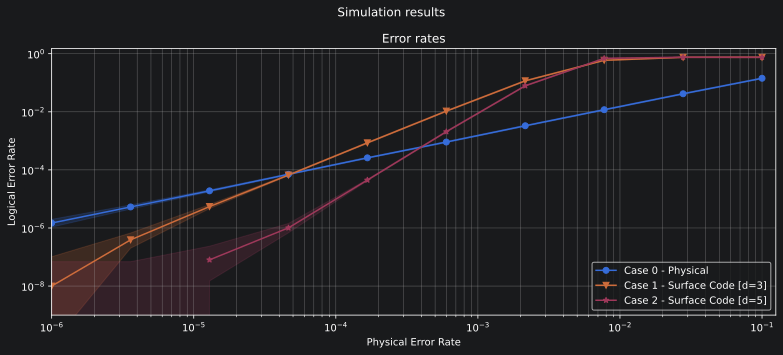

In [13]:
simulate(scenarios, shots=SHOTS, label="Case")

In [14]:
# from math import log10
#
# thresholds: list[float] = []
# for obs in blockgraph.find_correlation_surfaces():
#     threshold, _ = binary_search_threshold(
#         blockgraph,
#         obs,
#         NoiseModel.uniform_depolarizing,
#         manhattan_radius=2,
#         minp=10**-5,
#         maxp=0.1,
#         convention=FIXED_BULK_CONVENTION,
#         max_shots=MAX_SHOTS,
#         max_errors=MAX_ERRORS,
#         decoders=["pymatching"],
#     )
#     thresholds.append(threshold)
#
# log10_thresholds = [log10(t) for t in thresholds]
# mint, maxt = min(log10_thresholds), max(log10_thresholds)
# log10_threshold_bounds = (mint - 0.2, maxt + 0.2)

In [15]:
# fig, ax = plt.subplots()
# sinter.plot_error_rate(
#     ax=ax,
#     stats=ler_per_curve_stats,
#     x_func=lambda stat: stat.json_metadata["p"],
#     group_func=lambda stat: stat.json_metadata["d"],
# )
# xmin = 10 ** log10_threshold_bounds[0]
# xmax = 10 ** log10_threshold_bounds[1]
# # Note: the below values require prior knowledge about the values to look
# # for on the Y-axis.
# ymin, ymax = 1e-2, 3e-1
# plot_threshold_as_inset(
#     ax,
#     thres_stats,
#     # Note: ymax is **before** ymin because the y axis is inversed.
#     zoom_bounds=(xmin, ymax, xmax, ymin),
#     threshold=threshold,
#     inset_bounds=(0.5, 0.25, 0.4, 0.4),
# )
# ax.grid(which="both", axis="both")
# ax.legend()
# ax.loglog()
# ax.set_title("Z-basis memory error rate")
# ax.set_xlabel("Physical error rate (uniform depolarizing noise)")
# ax.set_ylabel("Logical error rate per shot")
# ax.set_ylim(10**-7.5, 10**0)

In [16]:
# circuit = stim.Circuit("""
#     RX 0
#     RZ 1
#     TICK
#     CX 0 1
#     TICK
#     MPP Z0*Z1
#     OBSERVABLE_INCLUDE(0) rec[-1]
# """)
# scenarios["No QEC"] = circuit
#
# circuit.diagram("timeline-svg")

In [17]:
# blockgraph = BlockGraph.from_dae_file("../../assets/logical_cnot.dae")
# surfaces = blockgraph.find_correlation_surfaces()